In [1]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

import os
os.makedirs("/kaggle/working/DLinear_Project/data/processed", exist_ok=True)
os.makedirs("/kaggle/working/DLinear_Project/results", exist_ok=True)

/kaggle/input/datasets/bchtrnng/daily-panel-parquet/daily_panel.parquet


In [2]:
%%writefile /kaggle/working/DLinear_Project/config.py

from pathlib import Path

BASE_DIR = Path("/kaggle/working/DLinear_Project")

# Update to your actual Kaggle dataset path
RAW_DATA_PATH = Path(
    "/kaggle/input/datasets/bchtrnng/daily-panel-parquet/daily_panel.parquet"
)

PROCESSED_DIR = BASE_DIR / "data" / "processed"
RESULTS_DIR = BASE_DIR / "results"

SEQ_LEN = 30
PRED_LEN = 7

TARGET = "quantity"
SERIES_KEYS = ["store_id", "item_id"]
SPLITS = ["train", "valid", "test"]

RANDOM_SEED = 42
# ==================================
# DLINEAR MODEL CONFIGURATION
# ==================================

ENC_IN = 1
INDIVIDUAL = False
KERNEL_SIZE = 25

BATCH_SIZE = 64

Writing /kaggle/working/DLinear_Project/config.py


In [3]:
%%writefile /kaggle/working/DLinear_Project/preprocessing.py

from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import joblib

from config import (
    RAW_DATA_PATH,
    PROCESSED_DIR,
    RESULTS_DIR,
    SEQ_LEN,
    PRED_LEN,
    SERIES_KEYS,
    SPLITS,
)


# ==========================================
# 1. LOAD AND SELECT DATA
# ==========================================

def load_data():
    print("========== LOAD DATA ==========")

    columns = [
        "date",
        "store_id",
        "item_id",
        "category",
        "group_name",
        "quantity",
        "phase",
        "promo_status",
        "depth",
        "split",
    ]

    df = pd.read_parquet(
        RAW_DATA_PATH,
        columns=columns
    )

    df["date"] = pd.to_datetime(df["date"])

    df = df.sort_values(
        SERIES_KEYS + ["date"]
    ).reset_index(drop=True)

    print("Rows:", len(df))
    print("Columns:", len(df.columns))

    return df


# ==========================================
# 2. VALIDATE DATA
# ==========================================

def validate_data(df):
    print("\n========== VALIDATION ==========")

    required = SERIES_KEYS + [
        "date", "quantity", "split"
    ]

    assert not df[required].isna().any().any(), (
        "Missing values in required columns"
    )

    assert (df["quantity"] >= 0).all(), (
        "Negative quantity found"
    )

    assert np.isfinite(df["quantity"]).all(), (
        "Non-finite quantity found"
    )

    assert not df.duplicated(
        SERIES_KEYS + ["date"]
    ).any(), "Duplicate series-date keys found"

    assert df["split"].isin(SPLITS).all(), (
        "Unexpected split label"
    )

    # One calendar day must belong to one split.
    assert (
        df.groupby("date")["split"].nunique().max() == 1
    ), "Split overlap detected"

    bounds = df.groupby("split")["date"].agg(
        ["min", "max"]
    )

    assert set(SPLITS).issubset(bounds.index)

    assert bounds.loc["train", "max"] < bounds.loc[
        "valid", "min"
    ]

    assert bounds.loc["valid", "max"] < bounds.loc[
        "test", "min"
    ]

    print("Data validation passed.")


# ==========================================
# 3. SCALE TARGET
# ==========================================

def scale_target(df):
    print("\n========== TARGET SCALING ==========")

    scaler = StandardScaler()

    train_mask = df["split"] == "train"

    # Fit only on training data.
    scaler.fit(
        df.loc[train_mask, ["quantity"]]
    )

    # Apply the same scaler to every split.
    df["quantity_scaled"] = (
        scaler.transform(df[["quantity"]])
        .ravel()
        .astype("float32")
    )

    PROCESSED_DIR.mkdir(
        parents=True, exist_ok=True
    )

    joblib.dump(
        scaler,
        PROCESSED_DIR / "scaler.joblib"
    )

    print("Train mean:", scaler.mean_[0])
    print("Train scale:", scaler.scale_[0])

    return df


# ==========================================
# 4. CREATE SLIDING WINDOW INDEX
# ==========================================

def build_window_index(df):
    print("\n========== BUILD WINDOWS ==========")

    windows = []
    audit = []

    window_size = SEQ_LEN + PRED_LEN

    # Group by individual product-store series.
    for (store_id, item_id), group in df.groupby(
        SERIES_KEYS, sort=False
    ):
        positions = group.index.to_numpy()
        dates = group["date"].to_numpy(
            dtype="datetime64[D]"
        )
        splits = group["split"].to_numpy()

        n = len(group)

        if n < window_size:
            audit.append({
                "store_id": store_id,
                "item_id": item_id,
                "observations": n,
                "valid_windows": 0,
                "reason": "too_short",
            })
            continue

        # True when adjacent dates are not 1 day apart.
        gaps = (
            np.diff(dates)
            != np.timedelta64(1, "D")
        )

        # Prefix sum enables O(1) gap checks.
        gap_prefix = np.concatenate([
            [0],
            np.cumsum(gaps.astype(np.int64))
        ])

        possible = n - window_size + 1
        valid_count = 0

        for start in range(possible):
            end = start + window_size - 1

            # Reject windows containing missing days.
            if gap_prefix[end] - gap_prefix[start] > 0:
                continue

            target_start = start + SEQ_LEN
            target_end = end

            # All 7 target dates must be in one split.
            target_split = splits[target_start]

            if target_split != splits[target_end]:
                continue

            # Historical input can precede the
            # target split, but must be earlier.
            windows.append({
                "store_id": store_id,
                "item_id": item_id,
                "start_pos": int(positions[start]),
                "target_start_pos": int(
                    positions[target_start]
                ),
                "target_end_pos": int(
                    positions[target_end]
                ),
                "input_start_date": str(dates[start]),
                "forecast_start_date": str(
                    dates[target_start]
                ),
                "forecast_end_date": str(
                    dates[target_end]
                ),
                "split": target_split,
            })

            valid_count += 1

        audit.append({
            "store_id": store_id,
            "item_id": item_id,
            "observations": n,
            "valid_windows": valid_count,
            "reason": (
                "eligible"
                if valid_count > 0
                else "no_valid_window"
            ),
        })

    windows_df = pd.DataFrame(windows)
    audit_df = pd.DataFrame(audit)

    return windows_df, audit_df


# ==========================================
# 5. VERIFY WINDOWS
# ==========================================

def verify_windows(df, windows):
    print("\n========== VERIFY WINDOWS ==========")

    assert not windows.empty, "No windows generated"

    starts = windows["start_pos"].to_numpy()
    target_starts = (
        windows["target_start_pos"].to_numpy()
    )
    target_ends = (
        windows["target_end_pos"].to_numpy()
    )

    assert np.all(
        target_starts == starts + SEQ_LEN
    )

    assert np.all(
        target_ends == target_starts + PRED_LEN - 1
    )

    # Windows are contiguous after sorting by
    # store_id, item_id and date.
    dates = df["date"].to_numpy(
        dtype="datetime64[D]"
    )

    assert np.all(
        dates[target_starts] - dates[starts]
        == np.timedelta64(SEQ_LEN, "D")
    )

    assert np.all(
        dates[target_ends] - dates[target_starts]
        == np.timedelta64(PRED_LEN - 1, "D")
    )

    # Target dates must match the declared split.
    split_array = df["split"].to_numpy()

    assert np.array_equal(
        split_array[target_starts],
        windows["split"].to_numpy()
    )

    assert np.array_equal(
        split_array[target_ends],
        windows["split"].to_numpy()
    )

    # Target begins after the input ends.
    assert np.all(
        dates[target_starts] > dates[target_starts - 1]
    )

    print("Window validation passed.")


# ==========================================
# 6. SAVE PROCESSED DATA
# ==========================================

def save_outputs(df, windows_df, audit_df):
    print("\n========== SAVE OUTPUTS ==========")

    PROCESSED_DIR.mkdir(
        parents=True, exist_ok=True
    )

    RESULTS_DIR.mkdir(
        parents=True, exist_ok=True
    )

    # Preserve row positions referenced by windows.
    df.to_parquet(
        PROCESSED_DIR / "daily_processed.parquet",
        index=False
    )

    windows_df.to_parquet(
        PROCESSED_DIR / "windows.parquet",
        index=False
    )

    audit_df.to_csv(
        RESULTS_DIR / "preprocessing_audit.csv",
        index=False
    )

    summary = windows_df["split"].value_counts()

    print("\nWindows by split:")
    print(summary.reindex(SPLITS, fill_value=0))

    print("\nSeries audit:")
    print(audit_df["reason"].value_counts())

    print("\nTotal valid windows:", len(windows_df))
    print("Output files saved.")


# ==========================================
# MAIN
# ==========================================

def main():
    df = load_data()
#return a dataframe
    validate_data(df)

    df = scale_target(df)
#normalize the target 
    windows_df, audit_df = build_window_index(df)
#windows_df: suitable window
#autdit_df: result of time series
    verify_windows(df, windows_df)

    save_outputs(df, windows_df, audit_df)

    print("\nPREPROCESSING COMPLETED")


if __name__ == "__main__":
    main()


Writing /kaggle/working/DLinear_Project/preprocessing.py


In [4]:
!cd /kaggle/working/DLinear_Project && python preprocessing.py
#import libaries, read functions -> main

========== LOAD DATA ==========
Rows: 1197327
Columns: 10

========== VALIDATION ==========
Data validation passed.

========== TARGET SCALING ==========
Train mean: 4.27369356887285
Train scale: 16.99248449898285

========== BUILD WINDOWS ==========

========== VERIFY WINDOWS ==========
Window validation passed.

========== SAVE OUTPUTS ==========

Windows by split:
split
train    705977
valid    179483
test     157320
Name: count, dtype: int64

Series audit:
reason
eligible           3163
too_short           895
no_valid_window       5
Name: count, dtype: int64

Total valid windows: 1042780
Output files saved.

PREPROCESSING COMPLETED


In [5]:
import pandas as pd

base = "/kaggle/working/DLinear_Project"

windows = pd.read_parquet(
    f"{base}/data/processed/windows.parquet"
)

audit = pd.read_csv(
    f"{base}/results/preprocessing_audit.csv"
)

print("Windows by split:")
print(windows["split"].value_counts())

print("\nSeries audit:")
print(audit["reason"].value_counts())

display(windows.head())
display(audit.head())

Windows by split:
split
train    705977
valid    179483
test     157320
Name: count, dtype: int64

Series audit:
reason
eligible           3163
too_short           895
no_valid_window       5
Name: count, dtype: int64


,store_id,item_id,start_pos,target_start_pos,target_end_pos,input_start_date,forecast_start_date,forecast_end_date,split
0,1,0062dbaa1e6e,34,64,70,2023-11-30,2023-12-30,2024-01-05,train
1,1,0062dbaa1e6e,35,65,71,2023-12-01,2023-12-31,2024-01-06,train
2,1,0062dbaa1e6e,36,66,72,2023-12-02,2024-01-01,2024-01-07,train
3,1,0062dbaa1e6e,37,67,73,2023-12-03,2024-01-02,2024-01-08,train
4,1,0062dbaa1e6e,38,68,74,2023-12-04,2024-01-03,2024-01-09,train


,store_id,item_id,observations,valid_windows,reason
0,1,0055c1d3ecd1,34,0,too_short
1,1,0062dbaa1e6e,301,253,eligible
2,1,0070437f5c2f,743,695,eligible
3,1,00cf67c74463,550,514,eligible
4,1,00e515fb935a,7,0,too_short


In [6]:
from pathlib import Path

BASE_DIR = Path("/kaggle/working/DLinear_Project")
PROCESSED_DIR = BASE_DIR / "data" / "processed"

required_files = [
    PROCESSED_DIR / "daily_processed.parquet",
    PROCESSED_DIR / "windows.parquet",
    PROCESSED_DIR / "scaler.joblib",
]

for path in required_files:
    print(path.name, ":", "FOUND" if path.exists() else "MISSING")

assert all(p.exists() for p in required_files), (
    "Missing Step 3 outputs. Run preprocessing.py first."
)

daily_processed.parquet : FOUND
windows.parquet : FOUND
scaler.joblib : FOUND


In [7]:
%%writefile /kaggle/working/DLinear_Project/dataset.py 

import numpy as np
import pandas as pd
import torch

from torch.utils.data import Dataset, DataLoader

from config import (
    PROCESSED_DIR,
    SEQ_LEN,
    PRED_LEN,
    SPLITS,
)


class RetailTimeSeriesDataset(Dataset):
    """
    PyTorch Dataset for daily retail demand forecasting.

    Uses sliding-window indices created in Step 3.
    Does NOT regenerate sliding windows.

    X shape: [SEQ_LEN, 1] //past
    Y shape: [PRED_LEN, 1] // future
    """

    def __init__(self, split="train"):
        super().__init__()

        if split not in SPLITS:
            raise ValueError(
                f"Invalid split: {split}. "
                f"Expected one of {SPLITS}"
            )

        self.split = split
        self.seq_len = SEQ_LEN
        self.pred_len = PRED_LEN

        # ----------------------------------
        # 1. Load processed data
        # ----------------------------------

        data_path = (
            PROCESSED_DIR / "daily_processed.parquet"
        )

        windows_path = (
            PROCESSED_DIR / "windows.parquet"
        )

        # Only load the columns required for training.
        df = pd.read_parquet(
            data_path,
            columns=["quantity_scaled"]
        )

        # Convert to NumPy for fast indexing.
        self.values = df[
            "quantity_scaled"
        ].to_numpy(dtype=np.float32, copy=True)

        # ----------------------------------
        # 2. Load existing window indices
        # ----------------------------------

        windows = pd.read_parquet(
            windows_path,
            columns=[
                "start_pos",
                "target_start_pos",
                "target_end_pos",
                "split"
            ]
        )

        # Select windows belonging to this split.
        windows = windows.loc[
            windows["split"] == split
        ]

        self.start_positions = (
            windows["start_pos"].to_numpy(
                dtype=np.int64,
                copy=True
            )
        )

        self.target_start_positions = (
            windows["target_start_pos"].to_numpy(
                dtype=np.int64,
                copy=True
            )
        )

        self.target_end_positions = (
            windows["target_end_pos"].to_numpy(
                dtype=np.int64,
                copy=True
            )
        )

        # ----------------------------------
        # 3. Validate index consistency
        # ----------------------------------

        if len(self.start_positions) == 0:
            raise ValueError(
                f"No windows found for split={split}"
            )

        if not np.all(
            self.target_start_positions
            - self.start_positions
            == self.seq_len
        ):
            raise ValueError(
                "Input window length mismatch"
            )

        if not np.all(
            self.target_end_positions
            - self.target_start_positions
            + 1 == self.pred_len
        ):
            raise ValueError(
                "Target window length mismatch"
            )

        if np.any(self.start_positions < 0):
            raise ValueError("Negative window position")

        if np.any(
            self.target_end_positions >= len(self.values)
        ):
            raise ValueError(
                "Window index exceeds data length"
            )

        print(
            f"{split.upper()} Dataset: "
            f"{len(self)} windows"
        )

    def __len__(self):
        """
        Number of valid windows in this split.
        """
        return len(self.start_positions)

    def __getitem__(self, index):
        """
        Return one (X, Y) window as PyTorch tensors.
        """

        start = int(self.start_positions[index])

        target_start = int(
            self.target_start_positions[index]
        )

        target_end = int(
            self.target_end_positions[index]
        )

        # ----------------------------------
        # Input: historical quantity
        # ----------------------------------

        x = self.values[
            start:target_start
        ]

        # ----------------------------------
        # Target: future quantity
        # ----------------------------------

        y = self.values[
            target_start:target_end + 1
        ]
        #x and y are still numpy array
        # Copy arrays before converting to tensors.
        # Add one channel dimension.
        x = torch.from_numpy(
            x.copy()
        ).unsqueeze(-1)

        y = torch.from_numpy(
            y.copy()
        ).unsqueeze(-1)
        # => x and y become PyTorch Tensor for DLinear
        return x, y

#organise the Sliding Windows into batches to provide data for the DLinear model

def create_dataloader(
    split="train",
    batch_size=64,
    num_workers=0
):
    """
    Create a PyTorch DataLoader.

    Shuffle only training windows.
    Validation and test stay in fixed order.
    """

    dataset = RetailTimeSeriesDataset(
        split=split #it is train
    )

    dataloader = DataLoader(
        dataset,
        batch_size=batch_size, #Maximum number of Sliding Windows in a batch = 64
        shuffle=(split == "train"), #it is train
        num_workers=num_workers, #Number of additional processes that
        #support batch retrieval of data
        pin_memory=torch.cuda.is_available(),
        drop_last=False #do not remove the last batch if it does not contain 64 samples
    )

    return dataloader


Writing /kaggle/working/DLinear_Project/dataset.py


In [8]:
import sys

PROJECT_DIR = "/kaggle/working/DLinear_Project"

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from dataset import create_dataloader

train_loader = create_dataloader(
    split="train",
    batch_size=64
)

valid_loader = create_dataloader(
    split="valid",
    batch_size=64
)

test_loader = create_dataloader(
    split="test",
    batch_size=64
)

TRAIN Dataset: 705977 windows
VALID Dataset: 179483 windows
TEST Dataset: 157320 windows


In [9]:
from dataset import RetailTimeSeriesDataset

train_dataset = RetailTimeSeriesDataset(
    split="train"
)

x, y = train_dataset[0]

print("X shape:", x.shape)
print("Y shape:", y.shape)

print("\nX dtype:", x.dtype)
print("Y dtype:", y.dtype)

print("\nX values:")
print(x.squeeze(-1))

print("\nY values:")

TRAIN Dataset: 705977 windows
X shape: torch.Size([30, 1])
Y shape: torch.Size([7, 1])

X dtype: torch.float32
Y dtype: torch.float32

X values:
tensor([-0.1927, -0.2515, -0.1338, -0.1927, -0.2515, -0.1927, -0.1927,  0.0427,
         0.1016,  0.2193,  0.3370, -0.1338,  0.0427,  0.5724,  0.8078, -0.1927,
        -0.0750, -0.0161,  0.1016,  0.2193, -0.1927, -0.1338,  0.1016,  0.1604,
        -0.0750,  0.0427, -0.0750, -0.0161, -0.2515, -0.1927])

Y values:


In [10]:
x_batch, y_batch = next(iter(train_loader))

print("X batch:", x_batch.shape)
print("Y batch:", y_batch.shape)

assert x_batch.shape == (64, 30, 1)
assert y_batch.shape == (64, 7, 1)

print("Batch shape validation passed.")

X batch: torch.Size([64, 30, 1])
Y batch: torch.Size([64, 7, 1])
Batch shape validation passed.


In [11]:
import torch

assert torch.isfinite(x_batch).all()
assert torch.isfinite(y_batch).all()

print("No NaN or Infinity in sampled batch.")

No NaN or Infinity in sampled batch.


In [12]:
import pandas as pd
import numpy as np

from config import PROCESSED_DIR

processed = pd.read_parquet(
    PROCESSED_DIR / "daily_processed.parquet"
)

windows = pd.read_parquet(
    PROCESSED_DIR / "windows.parquet"
)

first_window = windows[
    windows["split"] == "train"
].iloc[0]

start = int(first_window["start_pos"])
target_start = int(first_window["target_start_pos"])
target_end = int(first_window["target_end_pos"])

expected_x = processed[
    "quantity_scaled"
].iloc[start:target_start].to_numpy()

expected_y = processed[
    "quantity_scaled"
].iloc[target_start:target_end + 1].to_numpy()

actual_x, actual_y = train_dataset[0]

np.testing.assert_allclose(
    actual_x.squeeze(-1).numpy(),
    expected_x
)

np.testing.assert_allclose(
    actual_y.squeeze(-1).numpy(),
    expected_y
)

print("Dataset matches Step 3 window indices.")

Dataset matches Step 3 window indices.


In [13]:
from pathlib import Path

MODEL_DIR = Path("/kaggle/working/DLinear_Project/models")

MODEL_DIR.mkdir(parents=True, exist_ok=True)

(MODEL_DIR / "__init__.py").touch()

print("Model directory ready.")

Model directory ready.


In [14]:
%%writefile /kaggle/working/DLinear_Project/models/dlinear.py

import torch
import torch.nn as nn


# ==========================================
# 1. MOVING AVERAGE
# ==========================================

#smooth the sales time series to extract the Trend component.
class MovingAverage(nn.Module):
    """
    Extract a smoothed trend using moving average.

    Input:  [batch, seq_len, channels]
    Output: [batch, seq_len, channels]
    """
#kernel_size: the number of values used in each calculation of the moving average.
    def __init__(self, kernel_size=25):
        super().__init__()

        if kernel_size < 1 or kernel_size % 2 == 0:
            raise ValueError(
                "kernel_size must be a positive odd integer"
            )

        self.kernel_size = kernel_size

        self.avg = nn.AvgPool1d(
            kernel_size=kernel_size,
            stride=1,
            padding=0
        )

    def forward(self, x):

        pad = (self.kernel_size - 1) // 2

        # Repeat the boundary values to preserve
        # the original sequence length.
        front = x[:, :1, :].repeat(1, pad, 1)
        end = x[:, -1:, :].repeat(1, pad, 1)

        x = torch.cat(
            [front, x, end],
            dim=1
        )

        # AvgPool1d expects:
        # [batch, channels, seq_len]
        x = x.permute(0, 2, 1)

        x = self.avg(x)

        # Return to:
        # [batch, seq_len, channels]
        x = x.permute(0, 2, 1)

        return x


# ==========================================
# 2. SERIES DECOMPOSITION
# ==========================================

class SeriesDecomposition(nn.Module):
    """
    Decompose input time series into:
    - Remainder (seasonal in the original code)
    - Trend
    """

    def __init__(self, kernel_size=25):
        super().__init__()

        self.moving_avg = MovingAverage(
            kernel_size=kernel_size
        )

    def forward(self, x):

        trend = self.moving_avg(x)

        remainder = x - trend

        return remainder, trend


# ==========================================
# 3. DLINEAR MODEL
# ==========================================

class DLinear(nn.Module):
    """
    DLinear: Decomposition-Linear forecasting model.

    Reference:
    Zeng et al. (2023)
    Are Transformers Effective for Time Series Forecasting?

    Adapted from:
    https://github.com/honeywell21/DLinear

    Input:
        [batch_size, seq_len, channels]

    Output:
        [batch_size, pred_len, channels]
    """

    def __init__(
        self,
        seq_len=30,
        pred_len=7,
        channels=1,
        individual=False,
        kernel_size=25
    ):
        super().__init__()

        if seq_len <= 0 or pred_len <= 0 or channels <= 0:
            raise ValueError(
                "seq_len, pred_len, and channels must be positive"
            )

        self.seq_len = seq_len
        self.pred_len = pred_len
        self.channels = channels
        self.individual = individual

        # Decomposition layer
        ##initialise the SeriesDecomposition class that has been built previously.
        self.decomposition = SeriesDecomposition(
            kernel_size=kernel_size
        )

        # Separate linear layers for each channel
        if individual:

            self.linear_remainder = nn.ModuleList([
                nn.Linear(seq_len, pred_len)
                for _ in range(channels)
            ])

            self.linear_trend = nn.ModuleList([
                nn.Linear(seq_len, pred_len)
                for _ in range(channels)
            ])

        else:
            #a Linear layer for remainder and a Linear layer for trend, 
            #shared across all channels
            # Shared linear weights across channels.
            
            self.linear_remainder = nn.Linear(
                seq_len, pred_len
            )

            self.linear_trend = nn.Linear(
                seq_len, pred_len
            )
#data processing and generating forecast results.

    def forward(self, x):
#Check the input size
        if x.ndim != 3:
            raise ValueError(
                "Expected input shape "
                "[batch, seq_len, channels]"
            )

        if x.size(1) != self.seq_len:
            raise ValueError(
                f"Expected seq_len={self.seq_len}, "
                f"got {x.size(1)}"
            )

        if x.size(2) != self.channels:
            raise ValueError(
                f"Expected channels={self.channels}, "
                f"got {x.size(2)}"
            )

        # 1. Decompose input into remainder and train
        remainder, trend = self.decomposition(x)

        # [B, L, C] -> [B, C, L]
        #Because nn. Linear performs the transformation on the last dimension of the Tensor. 
        #We have nn. Linear(30, 7) Therefore, the final dimension must be 30.
        remainder = remainder.permute(0, 2, 1)
        trend = trend.permute(0, 2, 1)

        # 2. Linear forecasting
        if self.individual:

            remainder_out = torch.stack(
                [
                    self.linear_remainder[i](
                        remainder[:, i, :]
                    )
                    for i in range(self.channels)
                ],
                dim=1
            )

            trend_out = torch.stack(
                [
                    self.linear_trend[i](
                        trend[:, i, :]
                    )
                    for i in range(self.channels)
                ],
                dim=1
            )

        else: #predict fugure in remainder_out and trend_out

            remainder_out = self.linear_remainder(
                remainder
            )

            trend_out = self.linear_trend(
                trend
            )

        # 3. Combine forecasts
        output = remainder_out + trend_out
        
        #Restore the order of the dimensions
        # [B, C, pred_len] -> [B, pred_len, C]
        output = output.permute(0, 2, 1)

        return output


Writing /kaggle/working/DLinear_Project/models/dlinear.py


In [15]:
from pathlib import Path

config_path = Path(
    "/kaggle/working/DLinear_Project/config.py"
)

content = config_path.read_text(encoding="utf-8")

extra_config = """
# DLinear model configuration
ENC_IN = 1
INDIVIDUAL = False
KERNEL_SIZE = 25
BATCH_SIZE = 64
"""

if "ENC_IN =" not in content:
    with config_path.open("a", encoding="utf-8") as f:
        f.write("\n" + extra_config)

print("DLinear configuration ready.")

DLinear configuration ready.


In [16]:
import sys

PROJECT_DIR = "/kaggle/working/DLinear_Project"

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

import torch

from models.dlinear import DLinear

from config import (
    SEQ_LEN,
    PRED_LEN,
    ENC_IN,
    INDIVIDUAL,
    KERNEL_SIZE,
)

model = DLinear(
    seq_len=SEQ_LEN,
    pred_len=PRED_LEN,
    channels=ENC_IN,
    individual=INDIVIDUAL,
    kernel_size=KERNEL_SIZE
)

print(model)

DLinear(
  (decomposition): SeriesDecomposition(
    (moving_avg): MovingAverage(
      (avg): AvgPool1d(kernel_size=(25,), stride=(1,), padding=(0,))
    )
  )
  (linear_remainder): Linear(in_features=30, out_features=7, bias=True)
  (linear_trend): Linear(in_features=30, out_features=7, bias=True)
)


In [17]:
from dataset import create_dataloader
from config import BATCH_SIZE

train_loader = create_dataloader(
    split="train",
    batch_size=BATCH_SIZE,
    num_workers=0
)

x_batch, y_batch = next(iter(train_loader))

print("X batch shape:", x_batch.shape)
print("Y batch shape:", y_batch.shape)

model.eval()

with torch.no_grad():
    y_pred = model(x_batch)

print("X shape:", x_batch.shape)
print("Y true shape:", y_batch.shape)
print("Y predicted shape:", y_pred.shape)

assert y_pred.shape == y_batch.shape
assert torch.isfinite(y_pred).all()

print("DLinear successfully processed retail data!")

TRAIN Dataset: 705977 windows
X batch shape: torch.Size([64, 30, 1])
Y batch shape: torch.Size([64, 7, 1])
X shape: torch.Size([64, 30, 1])
Y true shape: torch.Size([64, 7, 1])
Y predicted shape: torch.Size([64, 7, 1])
DLinear successfully processed retail data!


In [18]:
import torch.nn as nn

criterion = nn.MSELoss()

model.train()
model.zero_grad()

y_pred = model(x_batch)

loss = criterion(y_pred, y_batch)

print("Initial MSE Loss:", loss.item())

assert torch.isfinite(loss)

loss.backward()

print("Backward pass successful!")

print("\n========== GRADIENT CHECK ==========")

for name, param in model.named_parameters():

    if param.requires_grad:

        if param.grad is None:
            raise RuntimeError(
                f"No gradient for parameter: {name}"
            )

        assert torch.isfinite(param.grad).all(), (
            f"Non-finite gradient: {name}"
        )

        print(
            name,
            "| Shape:", tuple(param.shape),
            "| Gradient norm:",
            param.grad.norm().item()
        )

print("\nGradient validation passed.")

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Initial MSE Loss: 0.4427086412906647
Backward pass successful!

========== GRADIENT CHECK ==========
linear_remainder.weight | Shape: (7, 30) | Gradient norm: 0.4912998676300049
linear_remainder.bias | Shape: (7,) | Gradient norm: 0.08083868771791458
linear_trend.weight | Shape: (7, 30) | Gradient norm: 1.2637662887573242
linear_trend.bias | Shape: (7,) | Gradient norm: 0.08083868771791458

Gradient validation passed.
Total parameters: 434
Trainable parameters: 434


In [19]:
import torch
import sys
from pathlib import Path

PROJECT_DIR = Path("/kaggle/working/DLinear_Project")

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

(PROJECT_DIR / "checkpoints").mkdir(
    parents=True, exist_ok=True
)

(PROJECT_DIR / "results").mkdir(
    parents=True, exist_ok=True
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cpu
Device: cpu


In [20]:
%%writefile /kaggle/working/DLinear_Project/train.py
#maiinn
import argparse
import copy
import random
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from dataset import create_dataloader
from models.dlinear import DLinear

from config import (
    BASE_DIR,
    RESULTS_DIR,
    SEQ_LEN,
    PRED_LEN,
)


# ==========================================
# 1. CONFIGURATION
# ==========================================
#Create a directory to save the results.

CHECKPOINT_DIR = BASE_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
#Setting up Training Hyperparameters

SEED = 42 #Control randomness
#Training has many random factors: weight initialisation, 
#batch shuffling... If the seed is not fixed, 
#each run will yield slightly different results, 
#making it difficult to compare models or reproduce results when writing reports.

MAX_EPOCHS = 20 #-> the loop does not run indefinitely

PATIENCE = 4 #The number of epochs allowed without improvement
MIN_DELTA = 1e-6 #Minimum improvement level to recognise a better result
#-> stop early when the model no longer improves on the validation set

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

#Set Random Seed
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ==========================================
# 2. TRAIN ONE EPOCH
# ==========================================
def train_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
):
    #Switch the model to Training mode
    model.train()

    total_loss = 0.0
    total_samples = 0

    for x_batch, y_batch in dataloader:

        x_batch = x_batch.to(
            DEVICE, non_blocking=True
        )
        y_batch = y_batch.to(
            DEVICE, non_blocking=True
        )

        # Clear gradients from previous batch
        optimizer.zero_grad(set_to_none=True)

        # Forward pass: start prediction
        predictions = model(x_batch)

        # Compute loss: measure the difference between the forecast and the actual value.
        loss = criterion(predictions, y_batch)

        # Backward pass: Each parameter should be adjusted in which direction?
        loss.backward()

        # Optional gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )
        # update weights based on the calculated gradient.
        optimizer.step()

        # Weighted average across batches
        batch_size = x_batch.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size
        
#average loss per sample of the entire epoch.
    return total_loss / total_samples


# ==========================================
# 3. VALIDATION
# ==========================================

@torch.no_grad()
def validate(
    model,
    dataloader,
    criterion,
):
    model.eval()

    total_loss = 0.0
    total_samples = 0

    for x_batch, y_batch in dataloader:

        x_batch = x_batch.to(
            DEVICE, non_blocking=True
        )
        y_batch = y_batch.to(
            DEVICE, non_blocking=True
        )

        predictions = model(x_batch)

        loss = criterion(predictions, y_batch)

        batch_size = x_batch.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


# ==========================================
# 4. TRAIN ONE EXPERIMENT
# ==========================================
#run a complete test: create data and model, 
#train for multiple epochs with early stopping, save the best model, 
#log the history, and then return the summary table.


def run_experiment(
    name,
    batch_size,
    learning_rate,
    kernel_size,
    weight_decay=0.0,
    max_epochs=MAX_EPOCHS,
    patience=PATIENCE,
):

    print("\n" + "=" * 55)
    print("EXPERIMENT:", name)
    print("=" * 55)

    set_seed(SEED)

    train_loader = create_dataloader(
        split="train",
        batch_size=batch_size,
        num_workers=0,
    )

    valid_loader = create_dataloader(
        split="valid",
        batch_size=batch_size,
        num_workers=0,
    )

    model = DLinear(
        seq_len=SEQ_LEN,
        pred_len=PRED_LEN,
        channels=1,
        individual=False,
        kernel_size=kernel_size,
    ).to(DEVICE)

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay,
    )

    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0

    history = []

    checkpoint_path = (
        CHECKPOINT_DIR / f"{name}.pt"
    )

    start_time = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
#start train
        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
        )

        val_loss = validate(
            model,
            valid_loader,
            criterion,
        )

        history.append({
            "experiment": name,
            "epoch": epoch,
            "train_mse": train_loss,
            "val_mse": val_loss,
        })

        print(
            f"Epoch {epoch:02d}/{max_epochs} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Val MSE: {val_loss:.6f}"
        )

        # Early stopping criterion
        if val_loss < best_val_loss - MIN_DELTA:

            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            # Store the best model only
            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "experiment": name,
                    "seq_len": SEQ_LEN,
                    "pred_len": PRED_LEN,
                    "channels": 1,
                    "individual": False,
                    "kernel_size": kernel_size,
                    "batch_size": batch_size,
                    "learning_rate": learning_rate,
                    "weight_decay": weight_decay,
                    "best_epoch": best_epoch,
                    "best_val_mse": best_val_loss,
                    "seed": SEED,
                },
                checkpoint_path,
            )

            print("  Best checkpoint saved.")

        else:
            #increase the counter; if patience is reached, then break
            epochs_without_improvement += 1

            if epochs_without_improvement >= patience:
                print("  Early stopping triggered.")
                break

    duration = time.perf_counter() - start_time

    history_df = pd.DataFrame(history)

    history_df.to_csv(
        RESULTS_DIR / f"{name}_history.csv",
        index=False,
    )

    result = {
        "experiment": name,
        "batch_size": batch_size,
        "learning_rate": learning_rate,
        "kernel_size": kernel_size,
        "weight_decay": weight_decay,
        "best_epoch": best_epoch,
        "best_val_mse": best_val_loss,
        "epochs_run": len(history),
        "duration_seconds": duration,
        "checkpoint": str(checkpoint_path),
    }

    print("\nBest epoch:", best_epoch)
    print("Best Validation MSE:", best_val_loss)
    print("Duration (seconds):", round(duration, 2))

    return result


# ==========================================
# 5. EXPERIMENT SELECTION
# ==========================================

def main():

    parser = argparse.ArgumentParser()

    parser.add_argument(
        "--mode",
        choices=["baseline", "tune"],
        default="baseline",
    )

    args = parser.parse_args()

    print("Training device:", DEVICE)

    if args.mode == "baseline":
        #only run 1 original configuration (batch 512, lr 0.001, kernel 25, no weight decay).
        #Used for quick runs, checking the pipeline.

        experiments = [
            {
                "name": "dlinear_baseline",
                "batch_size": 512,
                "learning_rate": 0.001,
                "kernel_size": 25,
                "weight_decay": 0.0,
            },
        ]

    else:
        #run 4 configurations. Each configuration only changes one hyperparameter 
        #compared to the baseline:

        #Baseline uses commonly default values, then each experiment 
        #only changes one hyperparameter. Thanks to this, if the val MSE changes,
        #we know that the cause is that factor.

        experiments = [
            {
                "name": "dlinear_baseline", #baseline
                "batch_size": 512,
                "learning_rate": 0.001,
                "kernel_size": 25,
                "weight_decay": 0.0,
            },
            {
                "name": "dlinear_lr_0005",
                "batch_size": 512,
                "learning_rate": 0.0005, #changed
                "kernel_size": 25,
                "weight_decay": 0.0,
            },
            {
                "name": "dlinear_kernel_7",
                "batch_size": 512,
                "learning_rate": 0.001,
                "kernel_size": 7, #changed
                "weight_decay": 0.0,
            },
            {
                "name": "dlinear_batch_256",
                "batch_size": 256, #changed
                "learning_rate": 0.001,
                "kernel_size": 25,
                "weight_decay": 0.0,
            },
        ]

    results = []
#Running experiments
    for experiment in experiments:
        result = run_experiment(**experiment)
        results.append(result)

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        "best_val_mse",
        ascending=True,
    )

    results_df.to_csv(
        RESULTS_DIR / "tuning_results.csv",
        index=False,
    )

    best = results_df.iloc[0]

    shutil.copyfile(
        best["checkpoint"],
        CHECKPOINT_DIR / "best_dlinear.pt",
    )

    print("\n========== FINAL RESULTS ==========")

    print(
        results_df[
            [
                "experiment",
                "batch_size",
                "learning_rate",
                "kernel_size",
                "best_epoch",
                "best_val_mse",
            ]
        ].to_string(index=False)
    )

    print("\nSelected experiment:", best["experiment"])
    print("Best Validation MSE:", best["best_val_mse"])
    print("Saved: checkpoints/best_dlinear.pt")


if __name__ == "__main__":
    main()


Writing /kaggle/working/DLinear_Project/train.py


In [21]:
!cd /kaggle/working/DLinear_Project && python train.py  --mode tune

Training device: cpu

EXPERIMENT: dlinear_baseline
TRAIN Dataset: 705977 windows
VALID Dataset: 179483 windows
Epoch 01/20 | Train MSE: 0.401759 | Val MSE: 0.273682
  Best checkpoint saved.
Epoch 02/20 | Train MSE: 0.360801 | Val MSE: 0.271997
  Best checkpoint saved.
Epoch 03/20 | Train MSE: 0.360100 | Val MSE: 0.270974
  Best checkpoint saved.
Epoch 04/20 | Train MSE: 0.360474 | Val MSE: 0.268446
  Best checkpoint saved.
Epoch 05/20 | Train MSE: 0.360377 | Val MSE: 0.268429
  Best checkpoint saved.
Epoch 06/20 | Train MSE: 0.360150 | Val MSE: 0.267572
  Best checkpoint saved.
Epoch 07/20 | Train MSE: 0.360088 | Val MSE: 0.270149
Epoch 08/20 | Train MSE: 0.360577 | Val MSE: 0.268575
Epoch 09/20 | Train MSE: 0.360601 | Val MSE: 0.269033
Epoch 10/20 | Train MSE: 0.360597 | Val MSE: 0.270175
  Early stopping triggered.

Best epoch: 6
Best Validation MSE: 0.2675723138332306
Duration (seconds): 216.56

EXPERIMENT: dlinear_lr_0005
TRAIN Dataset: 705977 windows
VALID Dataset: 179483 windows


In [22]:
import pandas as pd

results_path = (
    "/kaggle/working/DLinear_Project/"
    "results/tuning_results.csv"
)

results = pd.read_csv(results_path)

display(
    results[
        [
            "experiment",
            "batch_size",
            "learning_rate",
            "kernel_size",
            "best_epoch",
            "best_val_mse",
            "duration_seconds"
        ]
    ].sort_values("best_val_mse")
)

,experiment,batch_size,learning_rate,kernel_size,best_epoch,best_val_mse,duration_seconds
0,dlinear_lr_0005,512,0.0005,25,8,0.266802,251.018935
1,dlinear_kernel_7,512,0.0010,7,6,0.267311,197.268569
2,dlinear_baseline,512,0.0010,25,6,0.267572,216.560509
3,dlinear_batch_256,256,0.0010,25,2,0.269124,129.377008


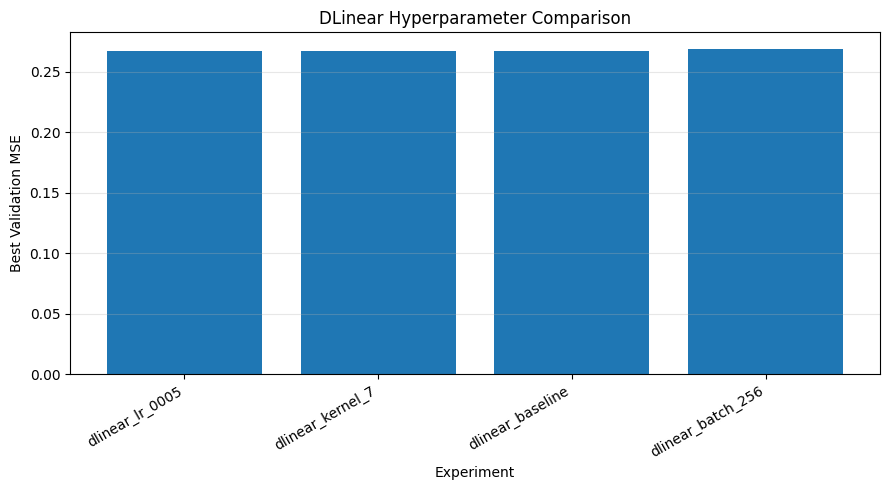

In [23]:
import matplotlib.pyplot as plt

results_sorted = results.sort_values(
    "best_val_mse"
)

plt.figure(figsize=(9, 5))

plt.bar(
    results_sorted["experiment"],
    results_sorted["best_val_mse"]
)

plt.xlabel("Experiment")
plt.ylabel("Best Validation MSE")
plt.title("DLinear Hyperparameter Comparison")

plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
import torch

from pathlib import Path
from models.dlinear import DLinear

checkpoint_path = Path(
    "/kaggle/working/DLinear_Project/"
    "checkpoints/best_dlinear.pt"
)

assert checkpoint_path.exists(), (
    "Best checkpoint not found."
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

best_model = DLinear(
    seq_len=checkpoint["seq_len"],
    pred_len=checkpoint["pred_len"],
    channels=checkpoint["channels"],
    individual=checkpoint["individual"],
    kernel_size=checkpoint["kernel_size"]
)

best_model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_model.eval()

print("Checkpoint loaded successfully.")
print("Best experiment:", checkpoint["experiment"])
print("Best epoch:", checkpoint["best_epoch"])
print("Best Validation MSE:", checkpoint["best_val_mse"])

Checkpoint loaded successfully.
Best experiment: dlinear_lr_0005
Best epoch: 8
Best Validation MSE: 0.266801933647826


In [25]:

%%writefile /kaggle/working/DLinear_Project/evaluate.py

import numpy as np
import pandas as pd
import torch
import joblib

from pathlib import Path

from config import (
    BASE_DIR,
    PROCESSED_DIR,
    RESULTS_DIR,
    SEQ_LEN,
    PRED_LEN,
)

from dataset import create_dataloader
from models.dlinear import DLinear


# ==========================================
# 1. SETTINGS
# ==========================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CHECKPOINT_DIR = BASE_DIR / "checkpoints"

TUNING_RESULTS_PATH = (
    RESULTS_DIR / "tuning_results.csv"
)

BATCH_SIZE = 512

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ==========================================
# 2. SELECT BEST TUNED CHECKPOINT
# ==========================================

def choose_checkpoint():
    """
    Select the experiment with the lowest
    Validation MSE from tuning_results.csv.

    Do not silently fall back to baseline.
    """

    if not TUNING_RESULTS_PATH.exists():
        raise FileNotFoundError(
            f"Tuning results not found: {TUNING_RESULTS_PATH}"
        )

    results = pd.read_csv(TUNING_RESULTS_PATH)

    required_columns = {
        "experiment",
        "best_val_mse",
    }

    if not required_columns.issubset(results.columns):
        raise ValueError(
            "Missing required columns in tuning_results.csv"
        )

    if results.empty:
        raise ValueError("Tuning results are empty")

    results["best_val_mse"] = pd.to_numeric(
        results["best_val_mse"],
        errors="coerce"
    )

    results = results.dropna(
        subset=["best_val_mse"]
    )

    results = results[
        np.isfinite(results["best_val_mse"])
    ]

    if results.empty:
        raise ValueError(
            "No valid Validation MSE found"
        )

    results = results.sort_values(
        "best_val_mse",
        ascending=True
    )

    best_row = results.iloc[0]

    experiment = str(best_row["experiment"])
    expected_mse = float(best_row["best_val_mse"])

    checkpoint_path = (
        CHECKPOINT_DIR / f"{experiment}.pt"
    )

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Best checkpoint not found: {checkpoint_path}"
        )

    print("\n========== MODEL SELECTION ==========")
    print("Selected experiment:", experiment)
    print("Expected Validation MSE:", expected_mse)
    print("Checkpoint path:", checkpoint_path)

    return checkpoint_path, experiment, expected_mse


# ==========================================
# 3. LOAD BEST MODEL
# ==========================================

def load_best_model():

    checkpoint_path, experiment, expected_mse = (
        choose_checkpoint()
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    if checkpoint["experiment"] != experiment:
        raise ValueError(
            "Checkpoint experiment does not match "
            "tuning_results.csv"
        )

    checkpoint_mse = float(
        checkpoint["best_val_mse"]
    )

    if not np.isclose(
        checkpoint_mse,
        expected_mse,
        rtol=1e-5,
        atol=1e-8
    ):
        raise ValueError(
            "Checkpoint Validation MSE does not match "
            "tuning_results.csv"
        )

    if checkpoint["seq_len"] != SEQ_LEN:
        raise ValueError("Sequence length mismatch")

    if checkpoint["pred_len"] != PRED_LEN:
        raise ValueError("Prediction length mismatch")

    if checkpoint["channels"] != 1:
        raise ValueError("Expected one input channel")

    model = DLinear(
        seq_len=checkpoint["seq_len"],
        pred_len=checkpoint["pred_len"],
        channels=checkpoint["channels"],
        individual=checkpoint["individual"],
        kernel_size=checkpoint["kernel_size"]
    ).to(DEVICE)

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.eval()

    print("\n========== BEST MODEL LOADED ==========")
    print("Experiment:", checkpoint["experiment"])
    print("Best epoch:", checkpoint["best_epoch"])
    print("Validation MSE:", checkpoint_mse)
    print("Learning rate:", checkpoint["learning_rate"])
    print("Batch size:", checkpoint["batch_size"])
    print("Kernel size:", checkpoint["kernel_size"])
    print("Weight decay:", checkpoint["weight_decay"])

    return model


# ==========================================
# 4. GENERATE TEST PREDICTIONS
# ==========================================

@torch.no_grad()
def generate_predictions(model):

    print("\n========== TEST PREDICTION ==========")

    test_loader = create_dataloader(
        split="test",
        batch_size=BATCH_SIZE,
        num_workers=0
    )

    predictions = []
    actuals = []
    naive_predictions = []

    for x_batch, y_batch in test_loader:

        x_device = x_batch.to(DEVICE)

        y_pred = model(x_device)

        predictions.append(
            y_pred.squeeze(-1).cpu().numpy()
        )

        actuals.append(
            y_batch.squeeze(-1).cpu().numpy()
        )

        # Seasonal Naive:
        # Forecast next 7 days using
        # the previous 7 observed days.
        naive_predictions.append(
            x_batch[:, -7:, 0].cpu().numpy().copy()
        )

    pred = np.concatenate(predictions, axis=0)

    actual_scaled = np.concatenate(
        actuals, axis=0
    )

    naive_scaled = np.concatenate(
        naive_predictions, axis=0
    )

    print("Prediction shape:", pred.shape)
    print("Actual shape:", actual_scaled.shape)
    print("Naive shape:", naive_scaled.shape)

    # ======================================
    # 5. VERIFY PREDICTION SHAPES
    # ======================================

    if not (
        pred.shape
        == actual_scaled.shape
        == naive_scaled.shape
    ):
        raise ValueError(
            "Prediction, actual and naive shapes differ"
        )

    if pred.ndim != 2 or pred.shape[1] != PRED_LEN:
        raise ValueError(
            "Prediction horizon mismatch"
        )

    # ======================================
    # 6. LOAD WINDOW METADATA
    # ======================================

    windows = pd.read_parquet(
        PROCESSED_DIR / "windows.parquet"
    )

    windows = windows.loc[
        windows["split"] == "test"
    ].reset_index(drop=True)

    if len(windows) != len(pred):
        raise ValueError(
            "Test windows and predictions are misaligned"
        )

    target_starts = windows[
        "target_start_pos"
    ].to_numpy(dtype=np.int64)

    target_ends = windows[
        "target_end_pos"
    ].to_numpy(dtype=np.int64)

    if not np.all(
        target_ends - target_starts + 1 == PRED_LEN
    ):
        raise ValueError(
            "Invalid test window indices"
        )

    # ======================================
    # 7. LOAD ORIGINAL DATA
    # ======================================

    raw = pd.read_parquet(
        PROCESSED_DIR / "daily_processed.parquet",
        columns=[
            "date",
            "store_id",
            "item_id",
            "category",
            "group_name",
            "phase",
            "quantity",
            "split"
        ]
    )

    # Generate target row positions
    indices = (
        target_starts[:, None]
        + np.arange(PRED_LEN)[None, :]
    ).reshape(-1)

    if indices.min() < 0 or indices.max() >= len(raw):
        raise ValueError("Target index out of range")

    target_rows = raw.iloc[indices].reset_index(
        drop=True
    )

    if not (target_rows["split"] == "test").all():
        raise ValueError(
            "Some targets are outside test split"
        )

    # Confirm that row positions match window metadata
    store_array = target_rows[
        "store_id"
    ].to_numpy().reshape(-1, PRED_LEN)

    item_array = target_rows[
        "item_id"
    ].to_numpy().reshape(-1, PRED_LEN)

    expected_stores = windows[
        "store_id"
    ].to_numpy()

    expected_items = windows[
        "item_id"
    ].to_numpy()

    if not np.all(
        store_array == expected_stores[:, None]
    ):
        raise ValueError(
            "Store metadata and window indices disagree"
        )

    if not np.all(
        item_array == expected_items[:, None]
    ):
        raise ValueError(
            "Item metadata and window indices disagree"
        )

    # ======================================
    # 8. INVERSE SCALING
    # ======================================

    scaler = joblib.load(
        PROCESSED_DIR / "scaler.joblib"
    )

    mean = float(scaler.mean_[0])
    scale = float(scaler.scale_[0])

    pred_original = pred * scale + mean

    actual_original = (
        actual_scaled * scale + mean
    )

    naive_original = (
        naive_scaled * scale + mean
    )

    actual = target_rows[
        "quantity"
    ].to_numpy(dtype=np.float64)

    if not np.allclose(
        actual_original.reshape(-1),
        actual,
        rtol=1e-4,
        atol=1e-4
    ):
        raise ValueError(
            "Inverse scaling mismatch"
        )

    # ======================================
    # 9. BUILD RESULT DATAFRAME
    # ======================================

    result = target_rows.drop(
        columns=["split", "quantity"]
    ).copy()

    result.insert(
        0,
        "window_id",
        np.repeat(np.arange(len(windows)), PRED_LEN)
    )

    result.insert(
        1,
        "horizon",
        np.tile(
            np.arange(1, PRED_LEN + 1),
            len(windows)
        )
    )

    result["actual"] = actual

    result["dlinear_pred"] = (
        pred_original.reshape(-1)
    )

    result["naive_pred"] = (
        naive_original.reshape(-1)
    )

    numeric_columns = [
        "actual",
        "dlinear_pred",
        "naive_pred"
    ]

    if not np.isfinite(
        result[numeric_columns].to_numpy()
    ).all():
        raise ValueError(
            "Non-finite values in predictions"
        )

    output_path = (
        RESULTS_DIR / "test_predictions.parquet"
    )

    result.to_parquet(
        output_path,
        index=False
    )

    print("Test windows:", len(windows))
    print("Forecast-target pairs:", len(result))
    print("Predictions saved:", output_path)

    return result


# ==========================================
# 10. EVALUATION METRICS
# ==========================================

def calculate_metrics(frame, prediction_col):

    actual = frame[
        "actual"
    ].to_numpy(dtype=np.float64)

    predicted = frame[
        prediction_col
    ].to_numpy(dtype=np.float64)

    error = predicted - actual

    mae = np.mean(np.abs(error))

    rmse = np.sqrt(
        np.mean(error ** 2)
    )

    denominator = np.sum(np.abs(actual))

    wape = (
        np.sum(np.abs(error)) / denominator * 100
        if denominator > 0
        else np.nan
    )

    bias = np.mean(error)

    return {
        "n_predictions": len(frame),
        "mae": mae,
        "rmse": rmse,
        "wape": wape,
        "bias": bias
    }


# ==========================================
# 11. COMPARE DLINEAR AND SEASONAL NAIVE
# ==========================================

def compare_models(frame):

    results = []

    models = [
        ("DLinear", "dlinear_pred"),
        ("Seasonal Naive", "naive_pred")
    ]

    for model_name, column in models:

        metrics = calculate_metrics(
            frame, column
        )

        metrics["model"] = model_name

        results.append(metrics)

    return pd.DataFrame(results)


# ==========================================
# 12. GROUPED EVALUATION
# ==========================================

def evaluate_by_group(frame, group_cols):

    results = []

    group_arg = (
        group_cols[0]
        if len(group_cols) == 1
        else group_cols
    )

    for group_key, subset in frame.groupby(
        group_arg,
        dropna=False
    ):

        if not isinstance(group_key, tuple):
            group_key = (group_key,)

        metrics = compare_models(subset)

        for col, value in zip(
            group_cols, group_key
        ):
            metrics[col] = value

        results.append(metrics)

    return pd.concat(
        results,
        ignore_index=True
    )


# ==========================================
# 13. MAIN EVALUATION
# ==========================================

def main():

    print("Device:", DEVICE)

    # Load best tuned DLinear model
    model = load_best_model()

    # Generate predictions on test data
    predictions = generate_predictions(model)

    # A. Overall metrics
    overall = compare_models(predictions)

    # B. Metrics by forecast horizon
    horizon_metrics = evaluate_by_group(
        predictions,
        ["horizon"]
    )

    # C. Metrics by product category
    category_metrics = evaluate_by_group(
        predictions,
        ["category"]
    )

    # D. Metrics by promotion phase
    promotion_metrics = evaluate_by_group(
        predictions,
        ["phase"]
    )

    # E. Category x promotion phase
    category_phase_metrics = evaluate_by_group(
        predictions,
        ["category", "phase"]
    )

    # F. Metrics by store
    store_metrics = evaluate_by_group(
        predictions,
        ["store_id"]
    )

    # G. One-day-ahead evaluation
    one_day = predictions.loc[
        predictions["horizon"] == 1
    ].copy()

    one_day_metrics = compare_models(one_day)

    # ======================================
    # SAVE RESULTS
    # ======================================

    analyses = {
        "overall_metrics.csv": overall,
        "horizon_metrics.csv": horizon_metrics,
        "category_metrics.csv": category_metrics,
        "promotion_metrics.csv": promotion_metrics,
        "category_phase_metrics.csv": category_phase_metrics,
        "store_metrics.csv": store_metrics,
        "one_day_metrics.csv": one_day_metrics
    }

    for filename, table in analyses.items():

        table.to_csv(
            RESULTS_DIR / filename,
            index=False
        )

        print(f"\n========== {filename} ==========")

        if filename in [
            "overall_metrics.csv",
            "horizon_metrics.csv",
            "one_day_metrics.csv"
        ]:
            print(table.to_string(index=False))
        else:
            print(f"Saved {len(table)} rows")

    print("\nSTEP 7 EVALUATION COMPLETED")


if __name__ == "__main__":
    main()


Writing /kaggle/working/DLinear_Project/evaluate.py


In [26]:
!cd /kaggle/working/DLinear_Project && python evaluate.py

Device: cpu

========== MODEL SELECTION ==========
Selected experiment: dlinear_lr_0005
Expected Validation MSE: 0.266801933647826
Checkpoint path: /kaggle/working/DLinear_Project/checkpoints/dlinear_lr_0005.pt

========== BEST MODEL LOADED ==========
Experiment: dlinear_lr_0005
Best epoch: 8
Validation MSE: 0.266801933647826
Learning rate: 0.0005
Batch size: 512
Kernel size: 25
Weight decay: 0.0

========== TEST PREDICTION ==========
TEST Dataset: 157320 windows
Prediction shape: (157320, 7)
Actual shape: (157320, 7)
Naive shape: (157320, 7)
Test windows: 157320
Forecast-target pairs: 1101240
Predictions saved: /kaggle/working/DLinear_Project/results/test_predictions.parquet

========== overall_metrics.csv ==========
 n_predictions      mae      rmse      wape     bias          model
       1101240 2.648474 12.020536 60.101306 0.001599        DLinear
       1101240 3.035284 14.909812 68.879109 0.030631 Seasonal Naive

========== horizon_metrics.csv ==========
 n_predictions      mae  

In [27]:
import pandas as pd

results_path = (
    "/kaggle/working/DLinear_Project/"
    "results/tuning_results.csv"
)

results = pd.read_csv(results_path)

display(
    results[
        [
            "experiment",
            "learning_rate",
            "batch_size",
            "kernel_size",
            "weight_decay",
            "best_epoch",
            "best_val_mse"
        ]
    ].sort_values("best_val_mse")
)

,experiment,learning_rate,batch_size,kernel_size,weight_decay,best_epoch,best_val_mse
0,dlinear_lr_0005,0.0005,512,25,0.0,8,0.266802
1,dlinear_kernel_7,0.0010,512,7,0.0,6,0.267311
2,dlinear_baseline,0.0010,512,25,0.0,6,0.267572
3,dlinear_batch_256,0.0010,256,25,0.0,2,0.269124


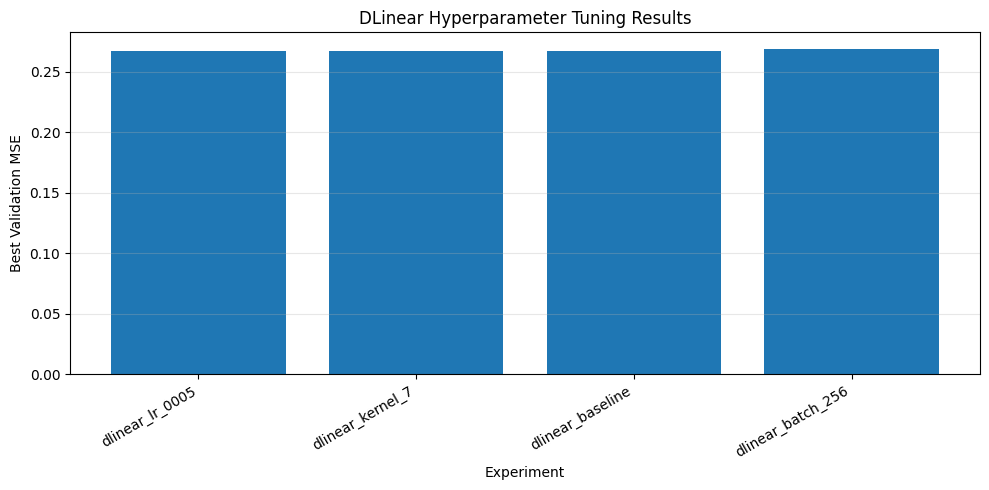

In [28]:
import matplotlib.pyplot as plt

results_sorted = results.sort_values("best_val_mse")

plt.figure(figsize=(10, 5))

plt.bar(
    results_sorted["experiment"],
    results_sorted["best_val_mse"]
)

plt.xlabel("Experiment")
plt.ylabel("Best Validation MSE")
plt.title("DLinear Hyperparameter Tuning Results")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [29]:
baseline_mse = results.loc[
    results["experiment"] == "dlinear_baseline",
    "best_val_mse"
].iloc[0]

best_row = results.loc[
    results["best_val_mse"].idxmin()
]

best_mse = best_row["best_val_mse"]

improvement = (
    (baseline_mse - best_mse) / baseline_mse
) * 100

print("Baseline Validation MSE:", baseline_mse)
print("Best Validation MSE:", best_mse)
print("Best experiment:", best_row["experiment"])

print(f"Improvement: {improvement:.2f}%")

Baseline Validation MSE: 0.2675723138332306
Best Validation MSE: 0.266801933647826
Best experiment: dlinear_lr_0005
Improvement: 0.29%


In [30]:
import torch

checkpoint_path = (
    "/kaggle/working/DLinear_Project/"
    "checkpoints/best_dlinear.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Best experiment:", checkpoint["experiment"])
print("Learning rate:", checkpoint["learning_rate"])
print("Batch size:", checkpoint["batch_size"])
print("Kernel size:", checkpoint["kernel_size"])
print("Weight decay:", checkpoint["weight_decay"])
print("Best epoch:", checkpoint["best_epoch"])
print("Validation MSE:", checkpoint["best_val_mse"])

Best experiment: dlinear_lr_0005
Learning rate: 0.0005
Batch size: 512
Kernel size: 25
Weight decay: 0.0
Best epoch: 8
Validation MSE: 0.266801933647826


In [31]:
%%writefile /kaggle/working/DLinear_Project/evaluate.py
#evaluation on the test set:

#pred: DLinear forecast (normalised), actual_scaled: actual value (normalised), 
#naive_scaled: naive model forecast (simple baseline, e.g., repeating the last value).
assert pred.shape == actual_scaled.shape == naive_scaled.shape

#check shape
    if pred.shape[1] != PRED_LEN:
        raise ValueError("Prediction horizon mismatch")
        
#Read the test set window table
    windows = pd.read_parquet(PROCESSED_DIR / "windows.parquet")
    windows = windows.loc[windows["split"] == "test"].reset_index(drop=True)
    if len(windows) != len(pred):
        raise ValueError("Test windows and DataLoader predictions are misaligned")
    if not np.all(windows["target_end_pos"].to_numpy() -
                  windows["target_start_pos"].to_numpy() + 1 == PRED_LEN):
        raise ValueError("Invalid test window indices")
        
#Read the original data and extract the target lines.
    raw = pd.read_parquet(
        PROCESSED_DIR / "daily_processed.parquet",
        columns=["date", "store_id", "item_id", "category", "group_name", "phase", "quantity", "split"],
    )
    indices = (windows["target_start_pos"].to_numpy(dtype=np.int64)[:, None] +
               np.arange(PRED_LEN)[None, :]).reshape(-1)
    if not (indices.min() >= 0 and indices.max() < len(raw)):
        raise ValueError("Target index out of range")
    target_rows = raw.iloc[indices].reset_index(drop=True)
    if not (target_rows["split"] == "test").all():
        raise ValueError("Some targets are outside test split")
    if not np.array_equal(
        target_rows["store_id"].to_numpy().reshape(-1, PRED_LEN)[:, 0],
        windows["store_id"].to_numpy(),
    ) or not np.array_equal(
        target_rows["item_id"].to_numpy().reshape(-1, PRED_LEN)[:, 0],
        windows["item_id"].to_numpy(),
    ):
        raise ValueError("Metadata and window indices disagree")

#Convert from the standardised scale to the original unit.
    scaler = joblib.load(PROCESSED_DIR / "scaler.joblib")
    mean, scale = float(scaler.mean_[0]), float(scaler.scale_[0])
    actual_from_scaled = actual_scaled * scale + mean
    actual = target_rows["quantity"].to_numpy(dtype=np.float64)
    if not np.allclose(actual_from_scaled.reshape(-1), actual, rtol=1e-4, atol=1e-4):
        raise ValueError("Scaled targets do not match original quantity")

    result = target_rows.drop(columns=["split", "quantity"]).copy()
    result.insert(0, "window_id", np.repeat(np.arange(len(windows)), PRED_LEN))
    result.insert(1, "horizon", np.tile(np.arange(1, PRED_LEN + 1), len(windows)))
    result["actual"] = actual
    result["dlinear_pred"] = (pred * scale + mean).reshape(-1)
    result["naive_pred"] = (naive_scaled * scale + mean).reshape(-1)
    if not np.isfinite(result[["actual", "dlinear_pred", "naive_pred"]].to_numpy()).all():
        raise ValueError("Non-finite predictions")

    result.to_parquet(RESULTS_DIR / "test_predictions.parquet", index=False)
    print("Test windows:", len(windows))
    print("Forecast-target pairs:", len(result))
    return result

#calculate metric
def calculate_metrics(frame, prediction_col):
    y = frame["actual"].to_numpy(dtype=np.float64)
    y_hat = frame[prediction_col].to_numpy(dtype=np.float64)
    error = y_hat - y
    denominator = np.abs(y).sum()
    return {
        "n_predictions": len(y),
        "mae": np.abs(error).mean(),
        "rmse": np.sqrt(np.mean(error ** 2)),
        "wape": np.abs(error).sum() / denominator * 100 if denominator > 0 else np.nan,
        "bias": error.mean(),
    }

#compare DLinear and Seasonal Naive
def compare_models(frame):
    rows = []
    for name, col in (("DLinear", "dlinear_pred"), ("Seasonal Naive", "naive_pred")):
        rows.append({"model": name, **calculate_metrics(frame, col)})
    return pd.DataFrame(rows)
    

#run compare_models for each subgroup of the forecast table (e.g., by phase, category, 
#horizon), then merge all into a single table
def evaluate_by_group(frame, group_cols):
    pieces = []
    group_arg = group_cols[0] if len(group_cols) == 1 else group_cols

    
    #Review each group
    for key, subset in frame.groupby(group_arg, dropna=False):
        key = key if isinstance(key, tuple) else (key,)
        
        #calculate metric
        metrics = compare_models(subset)
        for col, value in zip(group_cols, key):
            metrics[col] = value
        pieces.append(metrics)
    return pd.concat(pieces, ignore_index=True)


def main():
    print("Device:", DEVICE)
    
    #load the best model selected in the tuning step.
    model = load_best_model()

    #run the model on test windows, create a table
    predictions = generate_predictions(model)
    analyses = {
        "overall_metrics.csv": compare_models(predictions),
        "horizon_metrics.csv": evaluate_by_group(predictions, ["horizon"]),
        "category_metrics.csv": evaluate_by_group(predictions, ["category"]),
        "promotion_metrics.csv": evaluate_by_group(predictions, ["phase"]),
        "category_phase_metrics.csv": evaluate_by_group(predictions, ["category", "phase"]),
        "store_metrics.csv": evaluate_by_group(predictions, ["store_id"]),
        "one_day_metrics.csv": compare_models(predictions.loc[predictions["horizon"] == 1]),
    }

    
    for name, table in analyses.items():
        table.to_csv(RESULTS_DIR / name, index=False)
        print(f"\n========== {name} ==========")
        print(table.to_string(index=False) if name in (
            "overall_metrics.csv", "one_day_metrics.csv", "horizon_metrics.csv"
        ) else f"Saved {len(table)} rows")
    print("\nSTEP 7 EVALUATION COMPLETED")


if __name__ == "__main__":
    main()


Overwriting /kaggle/working/DLinear_Project/evaluate.py


,n_predictions,mae,rmse,wape,bias,model
0,1101240,2.648474,12.020536,60.101306,0.001599,DLinear
1,1101240,3.035284,14.909812,68.879109,0.030631,Seasonal Naive


MAE improvement: 12.74%


,n_predictions,mae,rmse,wape,bias,model,horizon
0,157320,2.378910,11.854891,53.853479,-0.000585,DLinear,1
1,157320,3.031900,14.803303,68.635786,0.024563,Seasonal Naive,1
2,157320,2.501130,11.976488,56.524319,-0.042782,DLinear,2
3,157320,3.041321,14.923252,68.732394,0.027755,Seasonal Naive,2
4,157320,2.625340,12.017242,59.335237,-0.021411,DLinear,3
5,157320,3.046306,14.971518,68.849480,0.024461,Seasonal Naive,3
6,157320,2.686224,11.984380,60.867522,-0.044199,DLinear,4
7,157320,3.042177,14.938634,68.933124,0.036343,Seasonal Naive,4
8,157320,2.746607,12.121004,62.380403,0.015397,DLinear,5
9,157320,3.034636,14.931392,68.922052,0.036843,Seasonal Naive,5


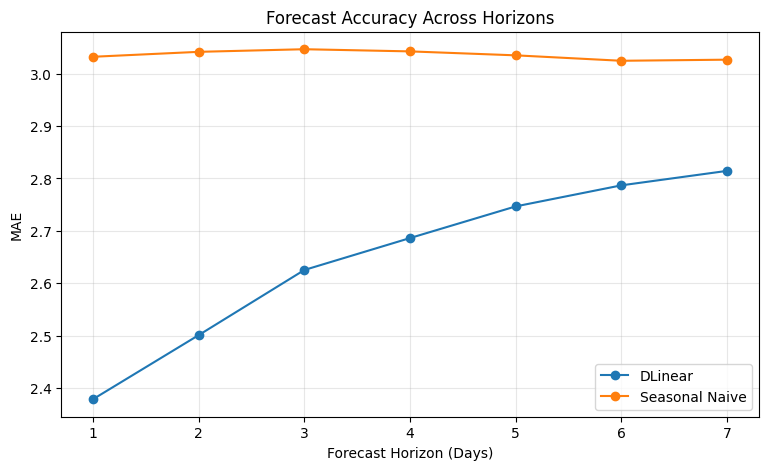

,n_predictions,mae,rmse,wape,bias,model,category
0,531342,4.461725,17.221712,55.578237,-0.174629,DLinear,food
1,531342,5.162460,21.350674,64.307059,0.067904,Seasonal Naive,food
2,569898,0.957897,1.639818,92.952464,0.165904,DLinear,household
3,569898,1.052020,2.134068,102.086010,-0.004120,Seasonal Naive,household


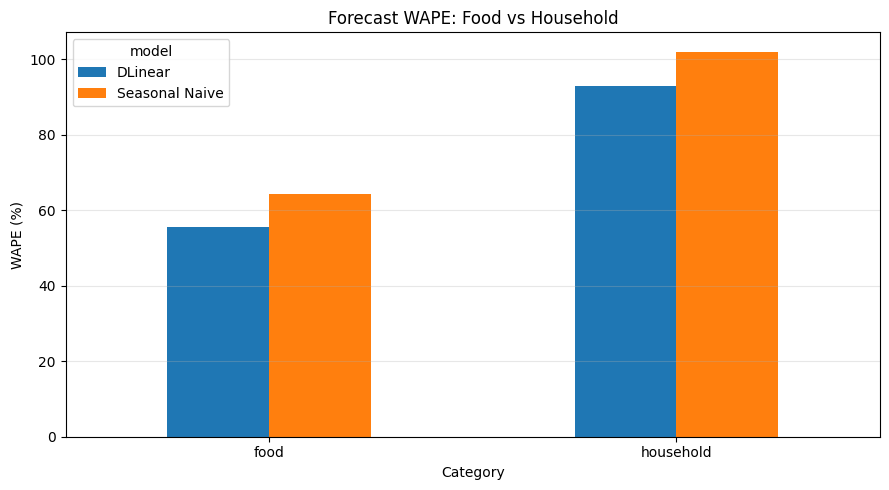

,n_predictions,mae,rmse,wape,bias,model,phase
0,144010,2.880237,9.655814,57.846301,-1.282032,DLinear,during
1,144010,3.300193,11.608090,66.280628,-1.291874,Seasonal Naive,during
2,856519,2.587170,12.432398,58.987539,0.099567,DLinear,other
3,856519,2.922730,15.574929,66.638314,0.056692,Seasonal Naive,other
4,31262,3.329696,13.568236,70.119016,0.996514,DLinear,post_1_3
5,31262,4.233371,13.705646,89.149210,2.183861,Seasonal Naive,post_1_3
6,41297,3.059686,10.202157,78.352977,1.372462,DLinear,post_4_7
7,41297,4.183959,13.494226,107.143543,2.469518,Seasonal Naive,post_4_7
8,28152,1.968358,10.751124,79.849746,0.471495,DLinear,pre_1_3
9,28152,2.089113,12.269460,84.748400,0.034138,Seasonal Naive,pre_1_3


,n_predictions,mae,rmse,wape,bias,model,category,phase
0,61430,5.510830,14.691856,53.389941,-2.788354,DLinear,food,during
1,61430,6.340953,17.654650,61.432334,-2.621012,Seasonal Naive,food,during
2,422360,4.233162,17.617340,54.647728,0.005757,DLinear,food,other
3,422360,4.818176,22.062054,62.199935,0.114427,Seasonal Naive,food,other
4,14958,5.962004,19.571640,62.710791,1.417256,DLinear,food,post_1_3
5,14958,7.701942,19.715411,81.012161,3.901581,Seasonal Naive,food,post_1_3
6,20155,5.415053,14.549952,71.104512,2.284760,DLinear,food,post_4_7
7,20155,7.550084,19.226177,99.139393,4.436154,Seasonal Naive,food,post_4_7
8,12439,3.692710,16.151526,71.732216,0.709124,DLinear,food,pre_1_3
9,12439,4.110035,18.428949,79.838901,0.079513,Seasonal Naive,food,pre_1_3


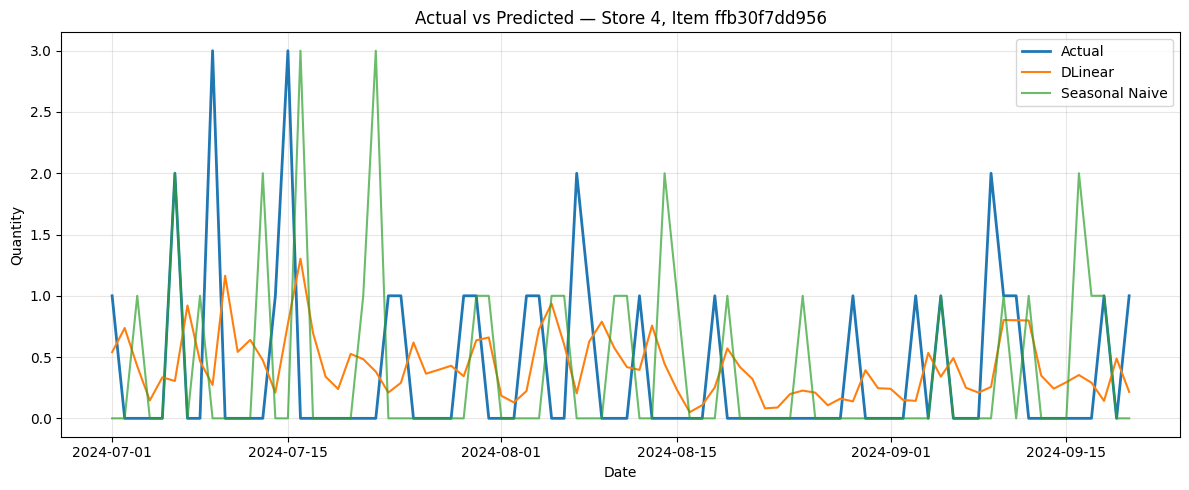

,n_predictions,mae,rmse,wape,bias,model
0,157320,2.37891,11.854891,53.853479,-0.000585,DLinear
1,157320,3.03190,14.803303,68.635786,0.024563,Seasonal Naive


In [32]:
import pandas as pd

RESULTS_DIR = (
    "/kaggle/working/DLinear_Project/results"
)

overall = pd.read_csv(
    f"{RESULTS_DIR}/overall_metrics.csv"
)

display(overall)
dlinear = overall.loc[
    overall["model"] == "DLinear"
].iloc[0]

naive = overall.loc[
    overall["model"] == "Seasonal Naive"
].iloc[0]

improvement = (
    (naive["mae"] - dlinear["mae"])
    / naive["mae"]
) * 100

print(f"MAE improvement: {improvement:.2f}%")
horizon = pd.read_csv(
    f"{RESULTS_DIR}/horizon_metrics.csv"
)

display(horizon)

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for model_name, group in horizon.groupby("model"):
    group = group.sort_values("horizon")

    plt.plot(
        group["horizon"],
        group["mae"],
        marker="o",
        label=model_name
    )

plt.xlabel("Forecast Horizon (Days)")
plt.ylabel("MAE")
plt.title("Forecast Accuracy Across Horizons")
plt.xticks(range(1, 8))
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

category = pd.read_csv(
    f"{RESULTS_DIR}/category_metrics.csv"
)

display(category)
import matplotlib.pyplot as plt

pivot = category.pivot(
    index="category",
    columns="model",
    values="wape"
)

ax = pivot.plot.bar(
    figsize=(9, 5),
    rot=0
)

ax.set_title("Forecast WAPE: Food vs Household")
ax.set_xlabel("Category")
ax.set_ylabel("WAPE (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

promotion = pd.read_csv(
    f"{RESULTS_DIR}/promotion_metrics.csv"
)

display(promotion)

category_phase = pd.read_csv(
    f"{RESULTS_DIR}/category_phase_metrics.csv"
)

display(category_phase)

import pandas as pd
import matplotlib.pyplot as plt

predictions = pd.read_parquet(
    f"{RESULTS_DIR}/test_predictions.parquet"
)

# One-day-ahead forecasts
one_day = predictions[
    predictions["horizon"] == 1
].copy()

# Select the product-store series with the
# largest number of available test predictions.
series_counts = (
    one_day.groupby(["store_id", "item_id"])
    .size()
    .sort_values(ascending=False)
)

store_id, item_id = series_counts.index[0]

selected = one_day[
    (one_day["store_id"] == store_id)
    & (one_day["item_id"] == item_id)
].sort_values("date")

plt.figure(figsize=(12, 5))

plt.plot(
    selected["date"],
    selected["actual"],
    label="Actual",
    linewidth=2
)

plt.plot(
    selected["date"],
    selected["dlinear_pred"],
    label="DLinear",
    linewidth=1.5
)

plt.plot(
    selected["date"],
    selected["naive_pred"],
    label="Seasonal Naive",
    alpha=0.7
)

plt.title(
    f"Actual vs Predicted — Store {store_id}, "
    f"Item {item_id}"
)

plt.xlabel("Date")
plt.ylabel("Quantity")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{RESULTS_DIR}/actual_vs_predicted.png",
    dpi=200
)

plt.show()

one_day_metrics = pd.read_csv(
    f"{RESULTS_DIR}/one_day_metrics.csv"
)

display(one_day_metrics)

========== DATA OVERVIEW ==========
Number of forecast-target pairs: 1101240
Columns: ['window_id', 'horizon', 'date', 'store_id', 'item_id', 'category', 'group_name', 'phase', 'actual', 'dlinear_pred', 'naive_pred']

========== OVERALL METRICS ==========


,n_predictions,MAE,RMSE,WAPE
0,1101240.0,2.6485,12.0205,60.1013



========== CATEGORY METRICS ==========


,category,n_predictions,WAPE
0,food,531342.0,55.5782
1,household,569898.0,92.9525



========== PROMOTION PHASE METRICS ==========


,phase,n_predictions,MAE,WAPE
0,pre_1_3,28152.0,1.9684,79.8497
1,during,144010.0,2.8802,57.8463
2,post_1_3,31262.0,3.3297,70.1190
3,post_4_7,41297.0,3.0597,78.3530
4,other,856519.0,2.5872,58.9875


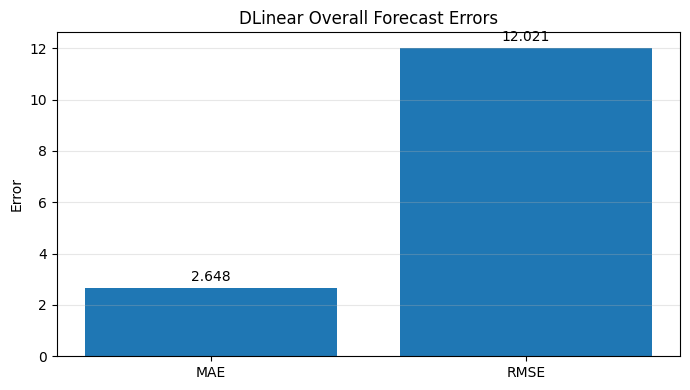

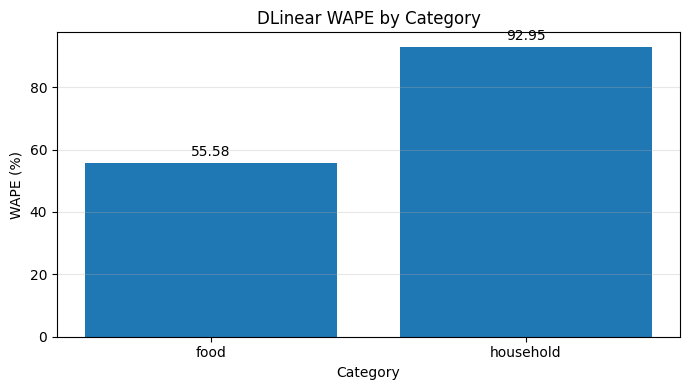

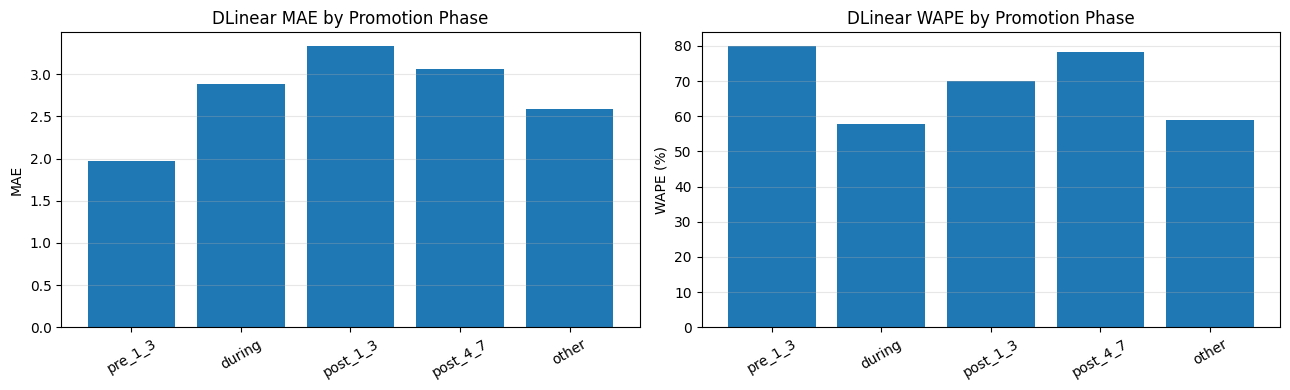


DLINEAR METRIC EVALUATION COMPLETED


In [33]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# 1. LOAD DLINEAR PREDICTIONS
# ==========================================

RESULTS_DIR = Path(
    "/kaggle/working/DLinear_Project/results"
)

df = pd.read_parquet(
    RESULTS_DIR / "test_predictions.parquet"
)

print("========== DATA OVERVIEW ==========")
print("Number of forecast-target pairs:", len(df))
print("Columns:", df.columns.tolist())

# Check required columns
required_columns = [
    "actual",
    "dlinear_pred",
    "category",
    "phase",
    "horizon"
]

assert all(
    col in df.columns
    for col in required_columns
), "Missing required columns"

assert np.isfinite(
    df[["actual", "dlinear_pred"]].to_numpy()
).all(), "NaN or Infinity detected"


# ==========================================
# 2. DEFINE EVALUATION METRICS
# ==========================================

def calculate_metrics(data):

    actual = data["actual"].to_numpy(
        dtype=np.float64
    )

    predicted = data["dlinear_pred"].to_numpy(
        dtype=np.float64
    )

    error = predicted - actual

    mae = np.mean(np.abs(error))

    rmse = np.sqrt(
        np.mean(error ** 2)
    )

    denominator = np.sum(np.abs(actual))

    wape = (
        np.sum(np.abs(error))
        / denominator * 100
        if denominator > 0
        else np.nan
    )

    return pd.Series({
        "n_predictions": len(data),
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape
    })


# ==========================================
# 3. OVERALL EVALUATION
# ==========================================

overall = calculate_metrics(df).to_frame().T

print("\n========== OVERALL METRICS ==========")
display(overall.round(4))

overall.to_csv(
    RESULTS_DIR / "dlinear_overall_metrics.csv",
    index=False
)


# ==========================================
# 4. FOOD / HOUSEHOLD EVALUATION
# ==========================================

category_metrics = (
    df.groupby("category")
    .apply(
        calculate_metrics,
        include_groups=False
    )
    .reset_index()
)

print("\n========== CATEGORY METRICS ==========")

display(
    category_metrics[
        ["category", "n_predictions", "WAPE"]
    ].round(4)
)

category_metrics.to_csv(
    RESULTS_DIR / "dlinear_category_metrics.csv",
    index=False
)


# ==========================================
# 5. PROMOTION PHASE EVALUATION
# ==========================================

phase_order = [
    "pre_1_3",
    "during",
    "post_1_3",
    "post_4_7",
    "other"
]

phase_metrics = (
    df.groupby("phase")
    .apply(
        calculate_metrics,
        include_groups=False
    )
    .reset_index()
)

phase_metrics["phase"] = pd.Categorical(
    phase_metrics["phase"],
    categories=phase_order,
    ordered=True
)

phase_metrics = (
    phase_metrics
    .sort_values("phase")
    .reset_index(drop=True)
)

print("\n========== PROMOTION PHASE METRICS ==========")

display(
    phase_metrics[
        ["phase", "n_predictions", "MAE", "WAPE"]
    ].round(4)
)

phase_metrics.to_csv(
    RESULTS_DIR / "dlinear_phase_metrics.csv",
    index=False
)


# ==========================================
# 6. VISUALIZATION: OVERALL METRICS
# ==========================================

fig, ax = plt.subplots(figsize=(7, 4))

values = overall[["MAE", "RMSE"]].iloc[0]

bars = ax.bar(
    values.index,
    values.values
)

ax.bar_label(
    bars,
    fmt="%.3f",
    padding=3
)

ax.set_title("DLinear Overall Forecast Errors")
ax.set_ylabel("Error")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================
# 7. VISUALIZATION: CATEGORY WAPE
# ==========================================

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    category_metrics["category"],
    category_metrics["WAPE"]
)

ax.bar_label(
    bars,
    fmt="%.2f",
    padding=3
)

ax.set_title("DLinear WAPE by Category")
ax.set_xlabel("Category")
ax.set_ylabel("WAPE (%)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================
# 8. VISUALIZATION: PROMOTION PHASE
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(
    phase_metrics["phase"].astype(str),
    phase_metrics["MAE"]
)

axes[0].set_title("DLinear MAE by Promotion Phase")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    phase_metrics["phase"].astype(str),
    phase_metrics["WAPE"]
)

axes[1].set_title("DLinear WAPE by Promotion Phase")
axes[1].set_ylabel("WAPE (%)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


print("\nDLINEAR METRIC EVALUATION COMPLETED")


In [34]:

%%writefile /kaggle/working/DLinear_Project/evaluate_weekly.py

import numpy as np
import pandas as pd
import torch
import joblib

from pathlib import Path

from config import (
    BASE_DIR,
    PROCESSED_DIR,
    RESULTS_DIR,
    SEQ_LEN,
    PRED_LEN,
)

from models.dlinear import DLinear


DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BATCH_SIZE = 512

KEYS = ["store_id", "item_id"]

CHECKPOINT_PATH = (
    BASE_DIR / "checkpoints" / "best_dlinear.pt"
)

PHASE_ORDER = [
    "pre_1_3",
    "during",
    "post_1_3",
    "post_4_7",
    "other"
]


# ==========================================
# 1. LOAD DATA
# ==========================================

def load_data():

    df = pd.read_parquet(
        PROCESSED_DIR / "daily_processed.parquet"
    )

    df["date"] = pd.to_datetime(df["date"])

    df = df.sort_values(
        KEYS + ["date"]
    ).reset_index(drop=True)

    assert not df.duplicated(
        KEYS + ["date"]
    ).any()

    test = df.loc[
        df["split"] == "test"
    ].copy()

    print("Total observations:", len(df))
    print("Test observations:", len(test))
    print("Test start:", test["date"].min())
    print("Test end:", test["date"].max())

    return df, test


# ==========================================
# 2. LOAD TRAINED MODEL
# ==========================================

def load_model():

    assert CHECKPOINT_PATH.exists(), (
        "Checkpoint not found. Run training first."
    )

    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=DEVICE,
        weights_only=False
    )

    assert checkpoint["seq_len"] == SEQ_LEN
    assert checkpoint["pred_len"] == PRED_LEN
    assert checkpoint["channels"] == 1

    model = DLinear(
        seq_len=checkpoint["seq_len"],
        pred_len=checkpoint["pred_len"],
        channels=checkpoint["channels"],
        individual=checkpoint["individual"],
        kernel_size=checkpoint["kernel_size"]
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model = model.to(DEVICE)

    model.eval()

    print("Loaded trained DLinear model")
    print("Experiment:", checkpoint["experiment"])
    print("Best epoch:", checkpoint["best_epoch"])

    return model


# ==========================================
# 3. LOAD SCALER
# ==========================================

def load_scaler():

    scaler = joblib.load(
        PROCESSED_DIR / "scaler.joblib"
    )

    return scaler


# ==========================================
# 4. BUILD HISTORICAL INPUTS
# ==========================================

def build_inputs(df, target, forecast_start):

    history_dates = pd.date_range(
        end=forecast_start - pd.Timedelta(days=1),
        periods=SEQ_LEN,
        freq="D"
    )

    history = df.loc[
        (df["date"] >= history_dates.min()) &
        (df["date"] < forecast_start)
    ].copy()

    # Product-store series with observed targets
    # in the current forecast block.
    series = target[
        KEYS + ["category"]
    ].drop_duplicates(
        subset=KEYS
    ).reset_index(drop=True)

    series_index = pd.MultiIndex.from_frame(
        series[KEYS]
    )

    # Create a calendar-aligned history matrix.
    # Rows: product-store series.
    # Columns: historical dates.
    history_matrix = history.pivot(
        index=KEYS,
        columns="date",
        values="quantity"
    )

    history_matrix = history_matrix.reindex(
        index=series_index,
        columns=history_dates
    )

    values = history_matrix.to_numpy(
        dtype=np.float64,
        copy=True
    )

    # Count available historical observations.
    history_days = np.isfinite(values).sum(axis=1)

    # Historical fallback by category and store.
    # Only data before the forecast start is used.
    group_prior = (
        history.groupby(
            ["store_id", "category"]
        )["quantity"]
        .mean()
        .to_dict()
    )

    # Fill missing historical observations.
    for i in range(len(series)):

        row = values[i]

        available = np.isfinite(row)

        if available.any():

            # Use the mean of available history.
            fill_value = row[available].mean()

        else:

            # Cold-start fallback.
            key = (
                series.loc[i, "store_id"],
                series.loc[i, "category"]
            )

            fill_value = group_prior.get(
                key, 0.0
            )

            if not np.isfinite(fill_value):
                fill_value = 0.0

        row[~available] = fill_value

        values[i] = row

    assert np.isfinite(values).all()

    series["history_days"] = history_days

    return series, values


# ==========================================
# 5. GENERATE MODEL FORECASTS
# ==========================================

def predict_batch(model, values, scaler):

    mean = float(scaler.mean_[0])
    scale = float(scaler.scale_[0])

    # Apply the original training scaler.
    x_scaled = (
        (values - mean) / scale
    ).astype(np.float32)

    predictions = []

    with torch.inference_mode():

        for start in range(
            0, len(x_scaled), BATCH_SIZE
        ):

            batch = x_scaled[
                start:start + BATCH_SIZE
            ]

            x = torch.from_numpy(
                batch
            ).unsqueeze(-1).to(DEVICE)

            output = model(x)

            output = (
                output.squeeze(-1)
                .cpu()
                .numpy()
            )

            predictions.append(output)

    predictions = np.concatenate(
        predictions,
        axis=0
    )

    assert predictions.shape == (
        len(values), PRED_LEN
    )

    # Inverse scaling.
    predictions = (
        predictions * scale + mean
    )

    # Demand cannot be negative.
    predictions = np.clip(
        predictions, 0, None
    )

    return predictions


# ==========================================
# 6. WEEKLY ROLLING-ORIGIN FORECASTING
# ==========================================

def generate_weekly_predictions(
    model, scaler, df, test
):

    test_start = test["date"].min()

    test_end = test["date"].max()

    forecast_starts = pd.date_range(
        start=test_start,
        end=test_end,
        freq=f"{PRED_LEN}D"
    )

    results = []

    for forecast_start in forecast_starts:

        forecast_end = min(
            forecast_start + pd.Timedelta(
                days=PRED_LEN - 1
            ),
            test_end
        )

        # Select actual test observations.
        target = test.loc[
            (test["date"] >= forecast_start) &
            (test["date"] <= forecast_end)
        ].copy()

        if target.empty:
            continue

        series, values = build_inputs(
            df,
            target,
            forecast_start
        )

        pred = predict_batch(
            model,
            values,
            scaler
        )

        # Map predictions to calendar dates.
        forecast = series.loc[
            series.index.repeat(PRED_LEN)
        ].reset_index(drop=True)

        forecast["horizon"] = np.tile(
            np.arange(1, PRED_LEN + 1),
            len(series)
        )

        forecast["date"] = (
            forecast_start
            + pd.to_timedelta(
                forecast["horizon"] - 1,
                unit="D"
            )
        )

        forecast["forecast_origin"] = (
            forecast_start
            - pd.Timedelta(days=1)
        )

        forecast["dlinear_pred"] = pred.reshape(-1)

        # Evaluate observed targets only.
        matched = target[
            KEYS + [
                "date",
                "quantity",
                "category",
                "phase"
            ]
        ].merge(
            forecast[
                KEYS + [
                    "date",
                    "horizon",
                    "forecast_origin",
                    "history_days",
                    "dlinear_pred"
                ]
            ],
            on=KEYS + ["date"],
            how="left",
            validate="one_to_one"
        )

        matched = matched.rename(
            columns={"quantity": "actual"}
        )

        assert matched[
            "dlinear_pred"
        ].notna().all()

        results.append(matched)

        print(
            f"{forecast_start.date()} -> "
            f"{forecast_end.date()} | "
            f"Predictions: {len(matched):,}"
        )

    predictions = pd.concat(
        results,
        ignore_index=True
    )

    predictions = predictions.sort_values(
        KEYS + ["date"]
    ).reset_index(drop=True)

    return predictions


# ==========================================
# 7. VERIFY PREDICTIONS
# ==========================================

def verify_predictions(predictions, test):

    key_columns = KEYS + ["date"]

    assert not predictions.duplicated(
        key_columns
    ).any(), "Duplicate predictions detected"

    assert len(predictions) == len(test), (
        "Test coverage mismatch"
    )

    expected = pd.MultiIndex.from_frame(
        test[key_columns]
    )

    predicted = pd.MultiIndex.from_frame(
        predictions[key_columns]
    )

    assert expected.difference(predicted).empty
    assert predicted.difference(expected).empty

    assert predictions["horizon"].between(
        1, PRED_LEN
    ).all()

    expected_horizon = (
        predictions["date"]
        - predictions["forecast_origin"]
    ).dt.days

    assert (
        expected_horizon == predictions["horizon"]
    ).all()

    assert (
        predictions["forecast_origin"]
        < predictions["date"]
    ).all()

    assert np.isfinite(
        predictions[
            ["actual", "dlinear_pred"]
        ].to_numpy()
    ).all()

    print("\n========== VERIFICATION ==========")

    print("Expected test rows:", len(test))

    print("Actual predictions:", len(predictions))

    print(
        "Duplicate predictions:",
        predictions.duplicated(
            key_columns
        ).sum()
    )

    print("Test coverage: 100%")
    print("Verification passed.")


# ==========================================
# 8. EVALUATION METRICS
# ==========================================

def calculate_metrics(frame):

    actual = frame["actual"].to_numpy(
        dtype=np.float64
    )

    predicted = frame["dlinear_pred"].to_numpy(
        dtype=np.float64
    )

    error = predicted - actual

    mae = np.mean(np.abs(error))

    rmse = np.sqrt(
        np.mean(error ** 2)
    )

    denominator = np.sum(
        np.abs(actual)
    )

    wape = (
        np.sum(np.abs(error))
        / denominator * 100
        if denominator > 0
        else np.nan
    )

    return {
        "n_predictions": len(frame),
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape,
        "Bias": np.mean(error)
    }


# ==========================================
# 9. GROUP-BASED EVALUATION
# ==========================================

def evaluate_by_group(frame, group_col):

    rows = []

    for group, subset in frame.groupby(group_col):

        row = {
            group_col: group,
            **calculate_metrics(subset)
        }

        rows.append(row)

    return pd.DataFrame(rows)


# ==========================================
# 10. SAVE RESULTS
# ==========================================

def save_results(predictions):

    RESULTS_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    overall = pd.DataFrame([
        {
            "Model": "DLinear",
            **calculate_metrics(predictions)
        }
    ])

    category = evaluate_by_group(
        predictions,
        "category"
    )

    phase = evaluate_by_group(
        predictions,
        "phase"
    )

    horizon = evaluate_by_group(
        predictions,
        "horizon"
    )

    phase["phase"] = pd.Categorical(
        phase["phase"],
        categories=PHASE_ORDER,
        ordered=True
    )

    phase = phase.sort_values(
        "phase"
    ).reset_index(drop=True)

    predictions.to_parquet(
        RESULTS_DIR / "weekly_test_predictions.parquet",
        index=False
    )

    overall.to_csv(
        RESULTS_DIR / "weekly_overall_metrics.csv",
        index=False
    )

    category.to_csv(
        RESULTS_DIR / "weekly_category_metrics.csv",
        index=False
    )

    phase.to_csv(
        RESULTS_DIR / "weekly_phase_metrics.csv",
        index=False
    )

    horizon.to_csv(
        RESULTS_DIR / "weekly_horizon_metrics.csv",
        index=False
    )

    print("\n========== OVERALL METRICS ==========")
    print(overall.to_string(index=False))

    print("\n========== CATEGORY METRICS ==========")
    print(category.to_string(index=False))

    print("\n========== PHASE METRICS ==========")
    print(phase.to_string(index=False))

    print("\n========== HORIZON METRICS ==========")
    print(horizon.to_string(index=False))


# ==========================================
# 11. MAIN
# ==========================================

def main():

    print("Device:", DEVICE)

    df, test = load_data()

    model = load_model()

    scaler = load_scaler()

    predictions = generate_weekly_predictions(
        model,
        scaler,
        df,
        test
    )

    verify_predictions(
        predictions,
        test
    )

    save_results(predictions)

    print("\nWEEKLY EVALUATION COMPLETED")


if __name__ == "__main__":
    main()


Writing /kaggle/working/DLinear_Project/evaluate_weekly.py


In [35]:
!cd /kaggle/working/DLinear_Project && python evaluate_weekly.py

Device: cpu
Total observations: 1197327
Test observations: 177713
Test start: 2024-07-01 00:00:00
Test end: 2024-09-26 00:00:00
Loaded trained DLinear model
Experiment: dlinear_lr_0005
Best epoch: 8
2024-07-01 -> 2024-07-07 | Predictions: 15,550
2024-07-08 -> 2024-07-14 | Predictions: 15,365
2024-07-15 -> 2024-07-21 | Predictions: 15,151
2024-07-22 -> 2024-07-28 | Predictions: 14,879
2024-07-29 -> 2024-08-04 | Predictions: 14,667
2024-08-05 -> 2024-08-11 | Predictions: 14,487
2024-08-12 -> 2024-08-18 | Predictions: 14,317
2024-08-19 -> 2024-08-25 | Predictions: 14,211
2024-08-26 -> 2024-09-01 | Predictions: 14,054
2024-09-02 -> 2024-09-08 | Predictions: 13,778
2024-09-09 -> 2024-09-15 | Predictions: 13,299
2024-09-16 -> 2024-09-22 | Predictions: 12,413
2024-09-23 -> 2024-09-26 | Predictions: 5,542

========== VERIFICATION ==========
Expected test rows: 177713
Actual predictions: 177713
Duplicate predictions: 0
Test coverage: 100%
Verification passed.

========== OVERALL METRICS =======

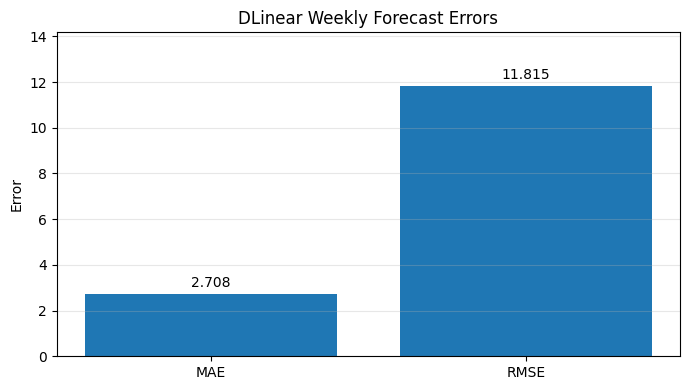

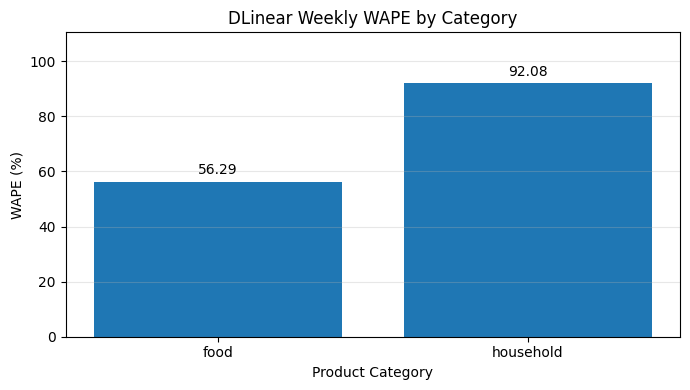

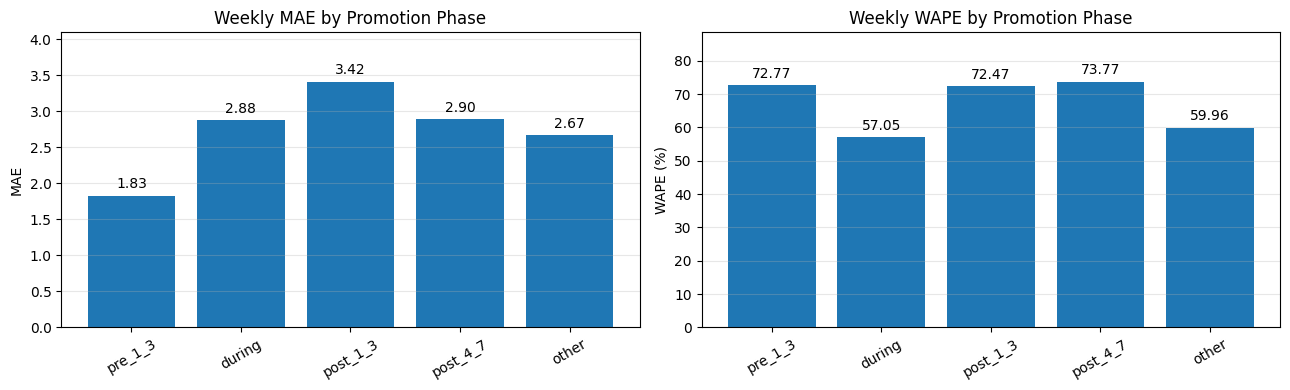

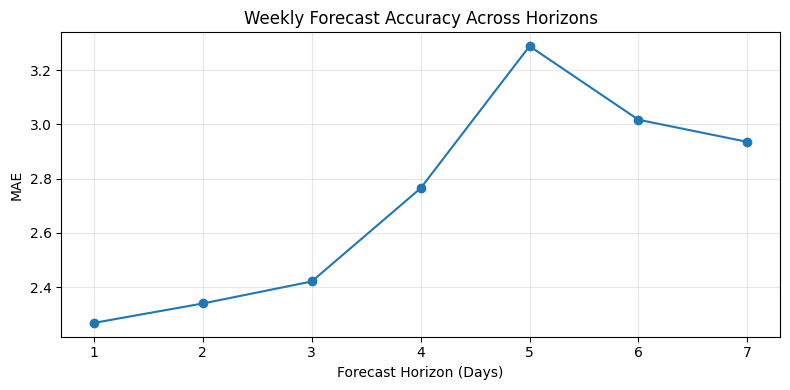

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path("/kaggle/working/DLinear_Project/results")

# Load kết quả WEEKLY (không dùng biến cũ trong notebook)
overall  = pd.read_csv(RESULTS_DIR / "weekly_overall_metrics.csv")
category = pd.read_csv(RESULTS_DIR / "weekly_category_metrics.csv")
phase    = pd.read_csv(RESULTS_DIR / "weekly_phase_metrics.csv")
horizon  = pd.read_csv(RESULTS_DIR / "weekly_horizon_metrics.csv")

phase_order = ["pre_1_3", "during", "post_1_3", "post_4_7", "other"]
phase["phase"] = pd.Categorical(phase["phase"], categories=phase_order, ordered=True)
phase = phase.sort_values("phase").reset_index(drop=True)
phase["phase"] = phase["phase"].astype(str)

# 1. Overall MAE & RMSE
fig, ax = plt.subplots(figsize=(7, 4))
values = overall[["MAE", "RMSE"]].iloc[0]
bars = ax.bar(values.index, values.values)
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_title("DLinear Weekly Forecast Errors")
ax.set_ylabel("Error")
ax.set_ylim(0, values.max() * 1.2)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "weekly_overall_errors.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. WAPE theo category
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(category["category"], category["WAPE"])
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_title("DLinear Weekly WAPE by Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("WAPE (%)")
ax.set_ylim(0, category["WAPE"].max() * 1.2)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "weekly_category_wape.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. MAE & WAPE theo promotion phase
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["MAE", "WAPE"]):
    bars = ax.bar(phase["phase"], phase[metric])
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set_title(f"Weekly {metric} by Promotion Phase")
    ax.set_ylabel("WAPE (%)" if metric == "WAPE" else "MAE")
    ax.set_ylim(0, phase[metric].max() * 1.2)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "weekly_phase_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

# 4. MAE theo horizon
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(horizon["horizon"], horizon["MAE"], marker="o")
ax.set_title("Weekly Forecast Accuracy Across Horizons")
ax.set_xlabel("Forecast Horizon (Days)")
ax.set_ylabel("MAE")
ax.set_xticks(range(1, 8))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "weekly_horizon_mae.png", dpi=300, bbox_inches="tight")
plt.show()

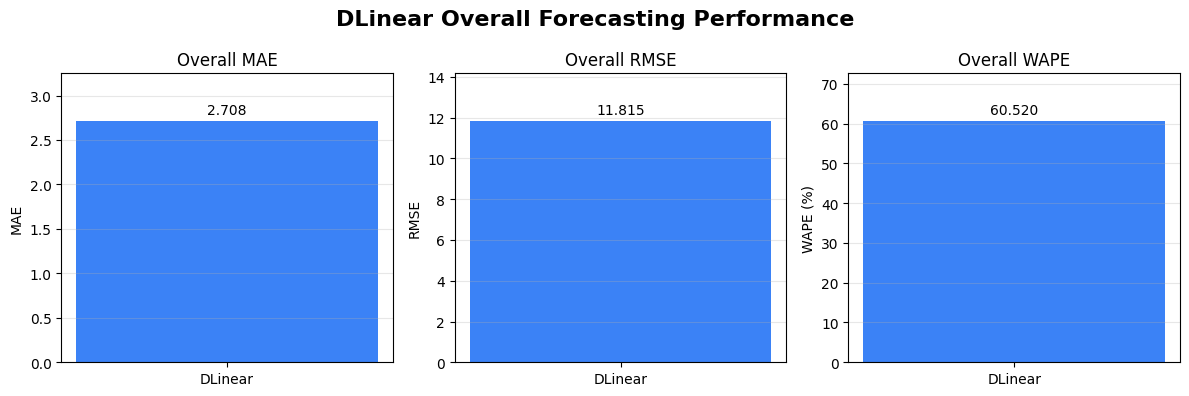

In [37]:
# ==========================================
# 1. OVERALL PERFORMANCE
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, metric in zip(
    axes, ["MAE", "RMSE", "WAPE"]
):

    value = overall[metric].iloc[0]

    bars = ax.bar(
        ["DLinear"],
        [value],
        width=0.4,
        color="#3B82F6"
    )

    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=3
    )

    ax.set_title(f"Overall {metric}")

    ax.set_ylabel(
        "WAPE (%)" if metric == "WAPE" else metric
    )

    ax.set_ylim(0, value * 1.2)

    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "DLinear Overall Forecasting Performance",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "weekly_overall_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import t as student_t

from sys import path

project_dir = Path("/kaggle/working/DLinear_Project")
if str(project_dir) not in path:
    path.insert(0, str(project_dir))

from config import RESULTS_DIR

keys = ["item_id", "store_id", "date"]
lstm_url = (
    "https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/"
    "LSTM_GridSearch/output/lstm/test_predictions.parquet"
)

dlinear = pd.read_parquet(
    RESULTS_DIR / "weekly_test_predictions.parquet",
    columns=keys + ["actual", "dlinear_pred", "horizon"],
)
lstm = pd.read_parquet(
    lstm_url,
    columns=keys + ["quantity", "lstm", "h"],
).rename(columns={
    "quantity": "actual_lstm",
    "lstm": "lstm_pred",
    "h": "horizon_lstm",
})

for frame in (dlinear, lstm):
    frame["item_id"] = frame["item_id"].astype(str)
    frame["store_id"] = frame["store_id"].astype(int)
    frame["date"] = pd.to_datetime(frame["date"]).dt.normalize()

matched = dlinear.merge(lstm, on=keys, how="inner", validate="one_to_one")

if len(matched) != len(dlinear) or len(matched) != len(lstm):
    raise ValueError("DLinear and LSTM have different test keys.")

np.testing.assert_allclose(
    matched["actual"], matched["actual_lstm"], rtol=0, atol=1e-6
)

if not matched["horizon"].eq(matched["horizon_lstm"]).all():
    raise ValueError("DLinear and LSTM use different forecast horizons for matched rows.")

actual = matched["actual"]
matched["abs_error_dlinear"] = (actual - matched["dlinear_pred"]).abs()
matched["abs_error_lstm"] = (actual - matched["lstm_pred"]).abs()
matched["loss_diff"] = matched["abs_error_dlinear"] - matched["abs_error_lstm"]

daily = matched.groupby("date", sort=True)["loss_diff"].sum()
expected_dates = pd.date_range("2024-07-01", "2024-09-26", freq="D")

if not daily.index.equals(expected_dates):
    raise ValueError("The matched predictions do not cover all 88 test days.")

# Newey–West variance with Bartlett weights and six lags
d = daily.to_numpy(dtype=float)
T = len(d)
H = 7
centered = d - d.mean()
variance = (centered @ centered) / T

for lag in range(1, H):
    covariance = (centered[lag:] @ centered[:-lag]) / T
    variance += 2 * (1 - lag / H) * covariance

if not np.isfinite(variance) or variance <= 0:
    raise ValueError("The estimated long-run variance must be positive and finite.")

# Harvey–Leybourne–Newbold small-sample correction
dm = d.mean() / np.sqrt(variance / T)
dm_hln = dm * np.sqrt((T + 1 - 2 * H + H * (H - 1) / T) / T)
p_value = 2 * student_t.sf(abs(dm_hln), df=T - 1)

result = pd.DataFrame([{
    "model_A": "DLinear",
    "model_B": "LSTM",
    "n_rows": len(matched),
    "T_days": T,
    "WAPE_A_pct": 100 * matched["abs_error_dlinear"].sum() / actual.sum(),
    "WAPE_B_pct": 100 * matched["abs_error_lstm"].sum() / actual.sum(),
    "DM_HLN": dm_hln,
    "p_value": p_value,
}])

result.to_csv(RESULTS_DIR / "dm_dlinear_vs_lstm.csv", index=False)
display(result)

,model_A,model_B,n_rows,T_days,WAPE_A_pct,WAPE_B_pct,DM_HLN,p_value
0,DLinear,LSTM,177713,88,60.519722,54.352055,11.777061,1.057266e-19


In [39]:
from importlib.util import module_from_spec, spec_from_file_location
from itertools import combinations
from pathlib import Path
import subprocess

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon


# 1. Paths and evaluation settings

PROJECT_DIR = Path("/kaggle/working/DLinear_Project")
REPO_DIR = Path("/kaggle/working/4_STAT3013_R11_dm")
REPO_URL = "https://github.com/tran04012006/4_STAT3013_R11.git"

PANEL_PATH = Path(
    "/kaggle/input/datasets/bchtrnng/daily-panel-parquet/daily_panel.parquet"
)
DLINEAR_PATH = PROJECT_DIR / "results" / "weekly_test_predictions.parquet"
OUTPUT_DIR = PROJECT_DIR / "results" / "dm_five_models"

KEYS = ["item_id", "store_id", "date"]
EXPECTED_DATES = pd.date_range("2024-07-01", "2024-09-26", freq="D")
EXPECTED_ROWS = 177_713
N_BOOT = 2_000
SEED = 42

for required_file in (PANEL_PATH, DLINEAR_PATH):
    if not required_file.is_file():
        raise FileNotFoundError(f"Missing required file: {required_file}")


# 2. Load the team's GitHub comparison script

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--branch", "LSTM_GridSearch", REPO_URL, str(REPO_DIR)],
        check=True,
    )
else:
    subprocess.run(["git", "fetch", "origin"], cwd=REPO_DIR, check=True)

script_path = REPO_DIR / "src" / "compare_models_dm.py"
spec = spec_from_file_location("team_compare_models_dm", script_path)
if spec is None or spec.loader is None:
    raise ImportError(f"Cannot load {script_path}")

team_dm = module_from_spec(spec)
spec.loader.exec_module(team_dm)

# This loads LSTM, NLinear-X and LightGBM predictions, and regenerates
# XGBoost predictions from the selected checkpoint using PANEL_PATH.
other_models = team_dm.load_all(str(PANEL_PATH))


# 3. Load DLinear and verify that the test rows match

dlinear = pd.read_parquet(
    DLINEAR_PATH,
    columns=KEYS + ["actual", "dlinear_pred", "horizon"],
).rename(columns={
    "actual": "actual_dlinear",
    "dlinear_pred": "pred_dlinear",
    "horizon": "h_dlinear",
})
dlinear = team_dm.norm_keys(dlinear)

if len(dlinear) != EXPECTED_ROWS or len(other_models) != EXPECTED_ROWS:
    raise ValueError(
        f"Expected {EXPECTED_ROWS:,} rows per input, got "
        f"DLinear={len(dlinear):,} and other models={len(other_models):,}."
    )

matched = other_models.merge(
    dlinear, on=KEYS, how="outer", validate="one_to_one", indicator=True
)

if not matched["_merge"].eq("both").all():
    raise ValueError(
        "Test keys differ across models:\n"
        + matched["_merge"].value_counts().to_string()
    )

matched = matched.drop(columns="_merge").sort_values(KEYS).reset_index(drop=True)

np.testing.assert_allclose(
    matched["quantity"],
    matched["actual_dlinear"],
    rtol=0,
    atol=1e-6,
    err_msg="Actual quantities differ between DLinear and the other models.",
)

if not matched["h_dlinear"].eq(matched["h"]).all():
    raise ValueError("DLinear and LSTM use different horizons for matched rows.")

test_dates = pd.DatetimeIndex(matched["date"].unique()).sort_values()
if not test_dates.equals(EXPECTED_DATES):
    raise ValueError("Matched predictions do not cover all 88 test days.")

prediction_columns = {
    "DLinear": "pred_dlinear",
    "NLinear-X": "pred_nlinear_x",
    "XGBoost": "pred_xgb",
    "LightGBM": "pred_lgb_b",
    "LSTM": "pred_lstm",
}

value_columns = ["quantity", *prediction_columns.values()]
if not np.isfinite(matched[value_columns].to_numpy(dtype=float)).all():
    raise ValueError("Actual quantities or predictions contain non-finite values.")


# 4. Compute DM, bootstrap CI and Wilcoxon for each pair

def compare_pairs(frame, evaluation, nw_lags):
    y = frame["quantity"].to_numpy(dtype=float)
    dates = frame["date"].to_numpy()

    if y.sum() <= 0:
        raise ValueError("Total actual quantity must be positive to compute WAPE.")

    # Each integer identifies one item–store series.
    series = frame.groupby(["item_id", "store_id"], sort=False).ngroup().to_numpy()
    errors = {
        model: np.abs(y - frame[column].to_numpy(dtype=float))
        for model, column in prediction_columns.items()
    }

    bootstrap = team_dm.Bootstrap(series, seed=SEED)
    mask = np.ones(len(frame), dtype=float)

    series_mae = pd.DataFrame(errors).groupby(series).mean()
    rows = []

    for model_a, model_b in combinations(prediction_columns, 2):
        error_a = errors[model_a]
        error_b = errors[model_b]

        dm_stat, dm_p, n_days = team_dm.dm_test(
            error_a, error_b, dates, lags=nw_lags
        )

        delta_wape, ci_low, ci_high = bootstrap(
            y, error_a, error_b, mask, N_BOOT
        )

        mae_diff = (series_mae[model_a] - series_mae[model_b]).to_numpy()

        # An all-zero difference has no signed ranks.
        if np.any(mae_diff != 0):
            signed_rank = wilcoxon(
                mae_diff,
                alternative="two-sided",
                zero_method="wilcox",
            )
            wilcoxon_stat = float(signed_rank.statistic)
            wilcoxon_p = float(signed_rank.pvalue)
        else:
            wilcoxon_stat = 0.0
            wilcoxon_p = 1.0

        rows.append({
            "evaluation": evaluation,
            "model_A": model_a,
            "model_B": model_b,
            "n_rows": len(frame),
            "T_days": n_days,
            "n_series": len(series_mae),
            "NW_lags": nw_lags,
            "HLN_correction": nw_lags == 6,
            "WAPE_A_pct": 100 * error_a.sum() / y.sum(),
            "WAPE_B_pct": 100 * error_b.sum() / y.sum(),
            "delta_WAPE_pp": delta_wape,
            "bootstrap_CI95_low_pp": ci_low,
            "bootstrap_CI95_high_pp": ci_high,
            "DM_stat": dm_stat,
            "DM_p_value": dm_p,
            "Wilcoxon_stat": wilcoxon_stat,
            "Wilcoxon_p_value": wilcoxon_p,
        })

    result = pd.DataFrame(rows)
    if len(result) != 10:
        raise ValueError(f"Expected 10 unique model pairs, got {len(result)}.")

    return result


# 5. Export the overall results and the matched-horizon comparison

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

overall = compare_pairs(matched, evaluation="all_test_dates", nw_lags=6)
overall_path = OUTPUT_DIR / "pairwise_tests_all_88_days.csv"
overall.to_csv(overall_path, index=False)

# DLinear, NLinear-X and LSTM output horizons 1–7.
# XGBoost and LightGBM use the seven-day historical cutoff.
# At h=7, all five are compared at the same forecast lead.
horizon_7 = matched.loc[matched["h"].eq(7)].copy()
if horizon_7["date"].nunique() != 12:
    raise ValueError("Expected 12 weekly forecast dates at horizon 7.")

# Match the team's weekly DM implementation: one lag and no HLN correction.
weekly = compare_pairs(horizon_7, evaluation="horizon_7_only", nw_lags=1)
weekly_path = OUTPUT_DIR / "pairwise_tests_horizon_7.csv"
weekly.to_csv(weekly_path, index=False)

print(f"Overall results: {overall_path}")
display(overall.round(6))

print(f"Same-horizon results: {weekly_path}")
display(weekly.round(6))

Cloning into '/kaggle/working/4_STAT3013_R11_dm'...


XGBoost: validation MSE 76.106 reproduced; 177,713 test predictions regenerated
Overall results: /kaggle/working/DLinear_Project/results/dm_five_models/pairwise_tests_all_88_days.csv


,evaluation,model_A,model_B,n_rows,T_days,n_series,NW_lags,HLN_correction,WAPE_A_pct,WAPE_B_pct,delta_WAPE_pp,bootstrap_CI95_low_pp,bootstrap_CI95_high_pp,DM_stat,DM_p_value,Wilcoxon_stat,Wilcoxon_p_value
0,all_test_dates,DLinear,NLinear-X,177713,88,2530,6,True,60.5197,56.4077,4.1120,3.4183,4.9429,16.7235,0.0000,"493,377.0000",0.0000
1,all_test_dates,DLinear,XGBoost,177713,88,2530,6,True,60.5197,58.7081,1.8116,0.9657,2.6719,3.8560,0.0002,"1,013,886.0000",0.0000
2,all_test_dates,DLinear,LightGBM,177713,88,2530,6,True,60.5197,57.2532,3.2665,2.3794,4.2637,6.2734,0.0000,"685,791.0000",0.0000
3,all_test_dates,DLinear,LSTM,177713,88,2530,6,True,60.5197,54.3520,6.1677,5.1788,7.2340,11.7771,0.0000,"420,726.0000",0.0000
4,all_test_dates,NLinear-X,XGBoost,177713,88,2530,6,True,56.4077,58.7081,-2.3004,-3.0284,-1.6690,-5.4033,0.0000,"1,045,452.0000",0.0000
5,all_test_dates,NLinear-X,LightGBM,177713,88,2530,6,True,56.4077,57.2532,-0.8455,-1.5857,-0.1284,-2.0143,0.0471,"1,423,866.0000",0.0000
6,all_test_dates,NLinear-X,LSTM,177713,88,2530,6,True,56.4077,54.3520,2.0556,1.3269,2.7781,5.1708,0.0000,"803,023.0000",0.0000
7,all_test_dates,XGBoost,LightGBM,177713,88,2530,6,True,58.7081,57.2532,1.4549,0.9790,1.9591,5.2714,0.0000,"936,132.0000",0.0000
8,all_test_dates,XGBoost,LSTM,177713,88,2530,6,True,58.7081,54.3520,4.3560,3.5668,5.2055,11.5732,0.0000,"609,539.0000",0.0000
9,all_test_dates,LightGBM,LSTM,177713,88,2530,6,True,57.2532,54.3520,2.9011,2.1404,3.6751,9.6782,0.0000,"837,591.0000",0.0000


Same-horizon results: /kaggle/working/DLinear_Project/results/dm_five_models/pairwise_tests_horizon_7.csv


,evaluation,model_A,model_B,n_rows,T_days,n_series,NW_lags,HLN_correction,WAPE_A_pct,WAPE_B_pct,delta_WAPE_pp,bootstrap_CI95_low_pp,bootstrap_CI95_high_pp,DM_stat,DM_p_value,Wilcoxon_stat,Wilcoxon_p_value
0,horizon_7_only,DLinear,NLinear-X,24317,12,2429,1,False,68.4249,62.1875,6.2373,5.0186,7.6160,12.3233,0.0000,"561,522.0000",0.0000
1,horizon_7_only,DLinear,XGBoost,24317,12,2429,1,False,68.4249,62.4214,6.0035,4.1533,7.9732,11.6056,0.0000,"538,472.0000",0.0000
2,horizon_7_only,DLinear,LightGBM,24317,12,2429,1,False,68.4249,60.6654,7.7594,6.0756,9.6874,9.1228,0.0000,"442,813.0000",0.0000
3,horizon_7_only,DLinear,LSTM,24317,12,2429,1,False,68.4249,61.5864,6.8385,4.6776,9.1746,6.8616,0.0000,"520,708.0000",0.0000
4,horizon_7_only,NLinear-X,XGBoost,24317,12,2429,1,False,62.1875,62.4214,-0.2339,-1.5914,0.9904,-0.4378,0.6700,"1,369,887.0000",0.0022
5,horizon_7_only,NLinear-X,LightGBM,24317,12,2429,1,False,62.1875,60.6654,1.5221,0.4569,2.5944,3.1120,0.0099,"1,331,707.0000",0.0000
6,horizon_7_only,NLinear-X,LSTM,24317,12,2429,1,False,62.1875,61.5864,0.6012,-0.6831,1.8984,0.8848,0.3952,"988,550.0000",0.0000
7,horizon_7_only,XGBoost,LightGBM,24317,12,2429,1,False,62.4214,60.6654,1.7560,0.9457,2.6224,3.1550,0.0092,"1,062,752.0000",0.0000
8,horizon_7_only,XGBoost,LSTM,24317,12,2429,1,False,62.4214,61.5864,0.8351,-0.3688,2.0965,1.1954,0.2571,"977,550.0000",0.0000
9,horizon_7_only,LightGBM,LSTM,24317,12,2429,1,False,60.6654,61.5864,-0.9209,-2.0986,0.1550,-1.9088,0.0827,"1,185,719.0000",0.0000
